<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/29_Adversarial_Robustness_Defences_for_QML/QNN_RandomizedEncoding_Gong2024.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Randomised unitary encoders against quantum adversarial attacks: barren plateaus for the attacker (Gong et al., 2024) step by step

This notebook re-implements, runs and checks the numerical experiments of

> Weiyuan Gong, Dong Yuan, Weikang Li and Dong-Ling Deng,
> "Enhancing quantum adversarial robustness by randomized encodings",
> Physical Review Research **6**, 023020 (2024). DOI 10.1103/PhysRevResearch.6.023020 (arXiv:2212.02531).

**What the notebook does.** A variational quantum classifier (VQC) learns to tell the two quantum phases of the *cluster-Ising chain*
apart from their ground states. An attacker appends a small variational circuit `U(theta)` (an "adversarial PVQC", started at the identity)
and follows the gradient of the classifier's loss to push the state over the decision boundary. The paper's defence is to wrap that
attack in a secret random unitary: Alice applies a random encoder `E` to the legitimate state, the attacker's circuit acts on the
*encoded* state, and Bob undoes the encoding with `E^dagger` before classifying (Fig. 1 and 2 of the paper). The paper proves that for a
2-design encoder the gradient of the attacker's loss has zero mean and a variance that shrinks exponentially with the number of qubits
(a **barren plateau for the attacker**, Theorems 1 and 2) and checks this numerically for 4 to 14 qubits (Fig. 3).
Here we (i) generate the cluster-Ising ground states exactly, (ii) train the paper's 10-layer classifier, (iii) measure the gradient
mean and variance of the adversarial circuit without defence, with a **global** random encoder and with a **local** (two-qubit-block)
random encoder for the same loss functions (KL divergence and normalised square loss), (iv) test the bound of Theorem 1 with *exact*
Haar-random encoders, (v) go beyond the paper with a small white-box attack experiment (clean vs adversarial accuracy with and
without the encoder) and classical baselines on identical inputs.

**How to run.** Google Colab, a CPU runtime is enough: *Runtime -> Run all*. `FAST_MODE = True` (default; 3 system sizes 4, 6, 8, small samples)
finishes in about 10 minutes on a laptop CPU (the committed outputs are from this run). `FAST_MODE = False` follows the paper's system sizes 4 to 14 qubits with the budgets listed in the configuration cell; it was **not** executed for this notebook (a first attempt was interrupted after about 35 minutes, and the estimate is well over 90 minutes on a shared laptop CPU), so the results below cover 4 to 8 qubits only.
There is **no dataset to download**: the dataset *is* the ground-state family of a spin Hamiltonian, which is computed here
(an exact sparse eigensolver, cached in `DATA_DIR`). No Hugging Face token is needed.

**What you get at the end.** The reproduction of Fig. 3 (a, b, c) and of the training curves of Fig. S1, a numerical check of the
variance bound of Theorem 1, a side-by-side table of the paper's claims and the notebook's numbers with a verdict per claim, a critical
reading and exercises.

## The paper in one page

**Problem.** Quantum classifiers are vulnerable to adversarial perturbations (tiny crafted changes of the input state). Adversarial
training is expensive and attack-specific. The paper asks for a defence that is attack-independent and provable.

**Idea.** Alice and Bob share a *codebook* `{p_i, E_i}` of encoders (random unitaries, or quantum-error-correcting encoders). For each
input Alice draws `E_i`, sends the encoded state plus the classical index `i`; Eve (the attacker) only ever sees encoded data; Bob
decodes with `E_i^dagger` and classifies. With the attacker's circuit `U(theta)` the loss becomes (Eq. 4)
`L(Theta, E_i; theta) = <psi| E_i^+ U^+ E_i V^+ H V E_i^+ U E_i |psi>`.

**Theory (not reproducible by simulation alone).**
* Theorem 1: for a unitary 2-design codebook, `E[dL/dtheta_l] = 0` and `Var[dL/dtheta_l] <= 2 Tr(A_l^2) / (d^2 - 1) * Tr(rho H_V^2)`, `d = 2^n`
  (barren plateau for *any* adversarial circuit `U(theta)` started at the identity, independent of the classifier).
* Theorem 2: block-wise 2-design encoders (`xi` blocks of `m` qubits) still give `Var <= O(((2^m+1)/(2^(2m)-1))^xi)`.
* Theorem 3: a local-unitary attacker changing only `O(1/sqrt(n))` of the qubits already causes a constant adversarial risk
  (concentration of measure) and Theorem 4: black-box QEC encoders (concatenated `O(log log n)` levels) bound the adversarial risk via
  quantum differential privacy. These are analytic; Section IV has no numerics.

**Numerics (what this notebook reproduces).** Data: ground states of the open cluster-Ising chain
`H(lambda) = - sum_{i=2}^{n-1} X_{i-1} Z_i X_{i+1} + lambda sum_i Y_i Y_{i+1}` for `lambda` in [0, 2]; label 0 (cluster phase) for
`lambda < 1`, label 1 (antiferromagnetic phase) for `lambda > 1`. Classifier: `P = 10` layers, each layer is two Euler-rotation units
`Z(theta) X(theta)` on every qubit and one CNOT chain, plus one ancilla qubit read out in the computational basis (n + 1 qubits); Adam optimiser.
Adversary: `L = 4`-layer circuit with a CNOT^dagger at the end of each layer so that all-zero angles give the identity. Encoder: 4-layer random
parametrised circuit (global) or tensor product of two-qubit random blocks (local, `m = 2`, two layers). Losses: KL divergence and normalised
square loss. Reported (Fig. 3, qualitative, no tables): (a) mean gradient -> 0 with more samples, (b) gradient variance decays exponentially from
4 to 14 qubits for global encoders, (c) the same for local encoders. Fig. S1: training/validation loss and accuracy of the 12-qubit classifier
(loss and accuracy "close", low over-fitting risk). The paper prints **no adversarial-accuracy numbers**.

### What follows the paper and what had to be chosen

The paper is a theory paper with a small numerical section (Appendix B). Everything unspecified is marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Hamiltonian, labels | `H(lambda)` Eq. (10), open boundary, label by `lambda < 1` / `> 1` | identical |
| Ground state | "compute the corresponding ground states" | exact sparse Lanczos solver on the bit-string basis. The open chain has a degenerate ground space (edge modes); the paper does not say which state it used. **Chosen:** the unique ground state in the sector where all Pauli symmetries of `H` (found by GF(2) linear algebra) equal +1, with a continuous sign gauge along `lambda` |
| Number of states, split | not stated | `lambda` on an even grid in (0, 2), 70 % train / 30 % validation (stratified); sizes in the config cell |
| Classifier | `P = 10` layers, Euler rotations `Z(d)X(c)`, CNOT chain, 1 ancilla, Adam, gradient by finite differences with `eps = 1e-10` | same architecture; exact adjoint gradients (`lightning.qubit`); Adam; **best-of-K random initialisations, then fine-tuning** (random deep circuits are hard to train with a plain random start) |
| Order of `Z(.)X(.)` | not stated | `X` rotation applied first, then `Z` |
| Adversary | `L = 4` layers, `U(theta_0) = I` via CNOT^dagger at the end of each layer, all angles 0 | identical; gradients at `theta_0 = 0` |
| Global encoder | 4-layer random PVQC (same layer type as the classifier) | identical, angles uniform in `[0, 2 pi)` |
| Local encoder | tensor product of two-qubit blocks, 2-layer, "inner structure in App. B" | identical blocks, 2 layers, independent random angles per block (even `n` only) |
| System sizes | 4 to 14 qubits | `FAST_MODE`: 4, 6, 8; full: 4, 6, 8, 10, 12, 14 |
| Samples for the statistics | not stated | per-size sample numbers in the config cell (each sample = random input state + random encoder) |
| "Variance averaged over parameters" | yes | per-parameter variance over samples, then averaged over all `16 n` adversary parameters; bootstrap 95 % interval |
| Losses | KL and normalised square loss | both, plus the expectation-value loss `<Z_ancilla>` that Theorem 1 actually treats |
| Control without defence | not shown | added: the same experiment with no encoder |
| Exact 2-design check | analytic | added: Haar-random encoders (QR of Ginibre matrices) compared with the bound of Eq. (6) |
| Adversarial accuracy under attack | not reported | **added as an extension, clearly labelled**: sign-gradient white-box attack, secret / guessed / leaked encoder |
| Classical baseline | none | SVC (RBF) and random forest on the same ground-state amplitude vectors, also evaluated on the attacked states (transfer) |
| Simulator | Yao.jl | PennyLane 0.45 `lightning.qubit` (adjoint gradients); asserted equal to `default.qubit` |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, scipy and matplotlib.
# Only PennyLane (and its fast C++ simulator "lightning") are added. The pip line runs on Colab (or wherever PennyLane is missing);
# a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("pennylane") is None or importlib.util.find_spec("pennylane_lightning") is None:
    %pip install -q "pennylane==0.45.1" "pennylane-lightning==0.45.0"
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("PennyLane and lightning already present; skipping pip install.")

PennyLane and lightning already present; skipping pip install.


In [2]:
# ------------------------------------------------------------------ configuration (every tunable constant lives here)
import os
os.environ.setdefault("OMP_NUM_THREADS", "2")      # CHOICE: keep the C++ simulator polite on shared machines (Colab has 2 cores anyway)

SEED = 42
FAST_MODE = True            # True: about 10 minutes on a laptop CPU. False: the paper's sizes 4..14 (about an hour on a laptop CPU)
IBM_TOKEN = ""              # unused: everything is simulated exactly (there is no hardware experiment in the paper)
DATA_DIR = "qc241_data"     # cache for the ground states

# architecture (paper, Appendix B)
P_CLF = 10                  # classifier layers
L_ADV = 4                   # adversarial circuit layers
L_ENC = 4                   # global encoder layers
L_LOC = 2                   # layers of each two-qubit block of the local encoder (m = 2)
P_SH = 2                    # layers of the SHALLOW control classifier (not in the paper)

if FAST_MODE:
    SIZES      = [4, 6, 8]                      # system sizes n (data qubits); the classifier has one more (ancilla) qubit
    N_STATES   = {4: 80, 6: 80, 8: 80}          # ground states per size (train + validation)
    TRAIN_K    = {4: 150, 6: 150, 8: 150}       # random initialisations ranked before fine-tuning
    TRAIN_ITERS = {4: 20, 6: 20, 8: 20}         # Adam iterations (fine-tuning)
    SEL_STATES = {4: 70, 6: 70, 8: 70}          # training states used to rank candidates
    N_GRAD     = {4: 80, 6: 80, 8: 60}          # (state, encoder) samples for the gradient statistics
    N_GRAD_SH  = {4: 40, 6: 40, 8: 30}          # the same for the shallow control classifier
    HAAR_SIZES = [4, 6]; N_HAAR = 60; HAAR_STATES = 2
    N_FIG      = 6                              # size for the training-curve figure (paper: 12 qubits)
    N_VIS      = 8                              # size for the dataset figures
    ATT_N, ATT_TEST, ATT_EPS, ATT_STEPS = 6, 16, [0.2], 5
else:
    SIZES      = [4, 6, 8, 10, 12, 14]
    N_STATES   = {4: 120, 6: 120, 8: 120, 10: 120, 12: 100, 14: 100}
    TRAIN_K    = {4: 400, 6: 400, 8: 300, 10: 120, 12: 10, 14: 6}
    TRAIN_ITERS = {4: 60, 6: 60, 8: 40, 10: 20, 12: 0, 14: 0}      # 12 and 14 qubits: ranking of random starts only (Adam steps are too slow on a laptop CPU)
    SEL_STATES = {4: 70, 6: 70, 8: 70, 10: 40, 12: 16, 14: 16}
    N_GRAD     = {4: 300, 6: 300, 8: 250, 10: 150, 12: 80, 14: 50}
    N_GRAD_SH  = {4: 100, 6: 100, 8: 80, 10: 60, 12: 40, 14: 30}
    HAAR_SIZES = [4, 6, 8]; N_HAAR = 200; HAAR_STATES = 4
    N_FIG      = 8                              # the paper shows 12 qubits; Adam fine-tuning at 12 qubits is too slow here
    N_VIS      = 8
    ATT_N, ATT_TEST, ATT_EPS, ATT_STEPS = 6, 40, [0.05, 0.1, 0.2], 10

TEST_SIZE = 0.3
BATCH = 16                  # CHOICE: mini-batch of the Adam steps
LR = 0.003                  # CHOICE: Adam learning rate
EPOCH_ITERS = 10            # the paper's "epoch" = 10 iterations (Fig. S1)
N_BOOT = 300                # bootstrap resamples for the variance intervals
print("FAST_MODE =", FAST_MODE, "| sizes", SIZES)

FAST_MODE = True | sizes [4, 6, 8]


In [3]:
import time, math, warnings
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy.sparse.linalg as sla
import scipy
import sklearn
import pennylane as qml
from pennylane import numpy as pnp
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3})
os.makedirs(DATA_DIR, exist_ok=True)

np.random.seed(SEED)
pnp.random.seed(SEED)                               # PennyLane's autograd numpy (used only for array creation here)
def rng_for(*tag):
    """Independent, reproducible random generators for every purpose (SEED, size, purpose)."""
    return np.random.default_rng([SEED, *tag])

print("numpy", np.__version__, "| scipy", scipy.__version__, "| sklearn", sklearn.__version__, "| pennylane", qml.__version__)
import pennylane_lightning
try:
    from importlib.metadata import version
    print("pennylane-lightning", version("pennylane-lightning"))
except Exception:
    pass

numpy 2.5.4 | scipy 1.18.1 | sklearn 1.9.1 | pennylane 0.45.1
pennylane-lightning 0.45.0


## 1. The model and the data: ground states of the cluster-Ising chain

The paper's dataset is not a file but a family of **quantum states**: for each coupling `lambda` in `[0, 2]` the ground state of

`H(lambda) = - sum_{i=2}^{n-1} X_{i-1} Z_i X_{i+1} + lambda * sum_{i=1}^{n-1} Y_i Y_{i+1}` (open chain, Eq. 10)

with Pauli matrices `X, Y, Z`. For `lambda < 1` the chain is in the *cluster* (symmetry-protected topological) phase, for `lambda > 1` in the
*antiferromagnetic* phase; the label of a state is the phase of its `lambda`. The classifier must decide the phase from the state alone.

**How we get the states exactly.** A Pauli string acts on a computational-basis vector by a bit flip plus a sign, so `H @ v` is a sum of
permuted, sign-flipped copies of `v`: no matrix is ever built and a 14-qubit ground state takes about a second.

**A subtlety the paper does not mention.** With open boundaries `H` has several Pauli symmetries (three, found below by linear algebra over GF(2)),
and the ground space is degenerate in the cluster phase (edge modes). "The ground state" is therefore not unique. We add a penalty
`6 * sum_s (1 - S_s)/2` that lifts every state with some symmetry eigenvalue `-1` and take the lowest state, i.e. the unique ground state of the sector in which
all symmetries equal +1. Its global sign is fixed by continuity along `lambda` (the overlap with the previous `lambda` is made positive).

In [4]:
# ------------------------------------------------------------------ exact ground states (bit-string Pauli algebra)
def pauli_masks(n, s):
    """Pauli string given as {wire: 'X'|'Y'|'Z'}; wire 0 is the most significant bit of the basis index."""
    xm = zm = ny = 0
    for w, p in s.items():
        b = 1 << (n - 1 - w)
        if p in "XY": xm |= b
        if p in "ZY": zm |= b
        if p == "Y": ny += 1
    return xm, zm, ny

def symmetry_strings(n):
    """Pauli strings that commute with every term of H(lambda): null space over GF(2) of the commutation matrix."""
    terms = [{i-1: "X", i: "Z", i+1: "X"} for i in range(1, n-1)] + [{i: "Y", i+1: "Y"} for i in range(n-1)]
    def vec(d):
        x = np.zeros(n, int); z = np.zeros(n, int)
        for i, p in d.items():
            if p in "XY": x[i] = 1
            if p in "ZY": z[i] = 1
        return np.concatenate([x, z])
    A = np.array([np.concatenate([vec(t)[n:], vec(t)[:n]]) for t in terms]) % 2
    M = A.copy(); rows, cols = M.shape; piv = []; r = 0
    for c in range(cols):
        p = next((i for i in range(r, rows) if M[i, c]), None)
        if p is None: continue
        M[[r, p]] = M[[p, r]]
        for i in range(rows):
            if i != r and M[i, c]: M[i] ^= M[r]
        piv.append(c); r += 1
        if r == rows: break
    out = []
    for f in [c for c in range(cols) if c not in piv]:
        v = np.zeros(cols, int); v[f] = 1
        for i, c in enumerate(piv):
            if M[i, f]: v[c] = 1
        d = {}
        for i in range(n):
            xb, zb = v[i], v[n + i]
            if xb and zb: d[i] = "Y"
            elif xb: d[i] = "X"
            elif zb: d[i] = "Z"
        out.append(d)
    return out

class PauliSum:
    """Real symmetric operator sum_t c_t P_t (strings with an even number of Y), applied without building a matrix."""
    def __init__(self, n, terms):
        self.n = n; self.N = 1 << n; idx = np.arange(self.N)
        self.perm, self.w = [], []
        for coef, d in terms:
            xm, zm, ny = pauli_masks(n, d)
            assert ny % 2 == 0
            par = np.zeros(self.N, dtype=np.uint8)
            for b in range(n):
                if (zm >> b) & 1: par ^= ((idx >> b) & 1).astype(np.uint8)
            self.perm.append(idx ^ xm)
            self.w.append(coef * ((-1) ** (ny // 2)) * (1 - 2.0 * par))
    def matvec(self, v):
        out = np.zeros_like(v)
        for p, w in zip(self.perm, self.w):
            out += (w * v)[p]
        return out

def cluster_ising_terms(n, lam):
    return [(-1.0, {i-1: "X", i: "Z", i+1: "X"}) for i in range(1, n-1)] + [(lam, {i: "Y", i+1: "Y"}) for i in range(n-1)]

def ground_state(n, lam, penalty=6.0):
    """Lowest eigenvector of H(lambda) + penalty * sum_s (1 - S_s)/2 (real, normalised) and its energy."""
    terms = cluster_ising_terms(n, lam)
    for s in symmetry_strings(n):
        terms += [(penalty / 2, {}), (-penalty / 2, s)]
    op = PauliSum(n, terms)
    A = sla.LinearOperator((op.N, op.N), matvec=op.matvec, dtype=float)
    w, v = sla.eigsh(A, k=1, which="SA", tol=1e-10)
    return v[:, 0] / np.linalg.norm(v[:, 0]), float(w[0])

# sanity checks against a dense matrix at n = 6
n_t = 6; op_t = PauliSum(n_t, cluster_ising_terms(n_t, 0.7))
H_t = np.array([op_t.matvec(e) for e in np.eye(2**n_t)]).T
psi_t, e_t = ground_state(n_t, 0.7)
print("H is symmetric:", np.allclose(H_t, H_t.T), "| residual |H psi - E psi| =", f"{np.linalg.norm(H_t @ psi_t - e_t * psi_t):.1e}")
for s in symmetry_strings(n_t):
    S_t = np.array([PauliSum(n_t, [(1.0, s)]).matvec(e) for e in np.eye(2**n_t)]).T
    print("symmetry", "".join(s.get(i, "I") for i in range(n_t)), "commutes with H:", np.allclose(H_t @ S_t, S_t @ H_t), "| <S> =", round(float(psi_t @ S_t @ psi_t), 6))

H is symmetric: True | residual |H psi - E psi| = 5.3e-13
symmetry ZXXZXX commutes with H: True | <S> = 1.0
symmetry XZXXZX commutes with H: True | <S> = 1.0
symmetry XXZXXZ commutes with H: True | <S> = 1.0


In [5]:
# ------------------------------------------------------------------ build / load the dataset for every size
def make_dataset(n, n_states):
    path = os.path.join(DATA_DIR, f"cluster_ising_n{n}_N{n_states}.npz")
    if os.path.exists(path):
        z = np.load(path); lams, X, E = z["lams"], z["X"], z["E"]
    else:
        lams = np.linspace(0.02, 1.98, n_states)          # CHOICE: even grid in (0, 2); an even count keeps lambda = 1 exactly out of the data
        X = np.zeros((n_states, 2**n)); E = np.zeros(n_states)
        for k, lam in enumerate(lams):
            psi, E[k] = ground_state(n, lam)
            if k == 0:
                psi = psi * np.sign(psi[np.argmax(np.abs(psi))])
            else:
                psi = psi * np.sign(psi @ X[k-1])         # continuous sign gauge along lambda
            X[k] = psi
        np.savez_compressed(path, lams=lams, X=X, E=E)
    y = (lams > 1).astype(int)                            # 0 = cluster phase (lambda < 1), 1 = antiferromagnetic (lambda > 1)
    tr, va = train_test_split(np.arange(len(y)), test_size=TEST_SIZE, stratify=y, random_state=SEED)
    return dict(lam=lams, X=X, y=y, E=E, tr=np.sort(tr), va=np.sort(va))

DATA = {}
t0 = time.time()
for n in SIZES:
    DATA[n] = make_dataset(n, N_STATES[n])
    print(f"n={n:2d}: {DATA[n]['X'].shape[0]} states of dimension {DATA[n]['X'].shape[1]}, "
          f"train {len(DATA[n]['tr'])} / validation {len(DATA[n]['va'])}, cumulative time {time.time()-t0:.1f}s")

n= 4: 80 states of dimension 16, train 56 / validation 24, cumulative time 0.3s
n= 6: 80 states of dimension 64, train 56 / validation 24, cumulative time 0.3s
n= 8: 80 states of dimension 256, train 56 / validation 24, cumulative time 0.4s


## 2. Dataset Exploration and Visualisation

Every observation here is a **real ground state** (a vector of `2^n` real amplitudes, one per computational basis state) computed from the
Hamiltonian of the paper; its label is the phase of its `lambda` (0 = cluster phase for `lambda < 1`, 1 = antiferromagnetic phase for `lambda > 1`).
Nothing is simulated from a class model and nothing is substituted. The classifier does not use angle encoding: the state is loaded directly
(`StatePrep`), so there is no `[0, pi]` angle scaling to show; the 2-D map below uses the raw amplitudes (PCA fitted on the training split only).

In [6]:
# ------------------------------------------------------------------ shapes, features, labels
summary = pd.DataFrame([{"n qubits": n, "states (rows)": DATA[n]["X"].shape[0], "features (2^n amplitudes)": DATA[n]["X"].shape[1],
                         "train": len(DATA[n]["tr"]), "validation": len(DATA[n]["va"]),
                         "class 0 (cluster, lambda<1)": int((DATA[n]["y"] == 0).sum()), "class 1 (AFM, lambda>1)": int((DATA[n]["y"] == 1).sum())} for n in SIZES])
display(summary)
d = DATA[N_VIS]
print(f"\nDataset used for the figures: n = {N_VIS}, X shape = {d['X'].shape}, labels shape = {d['y'].shape}")
names = [format(b, f"0{N_VIS}b") for b in range(2**N_VIS)]
print("feature names (first 4 / last 2):", [f"<{s}|psi>" for s in names[:4]], "...", [f"<{s}|psi>" for s in names[-2:]])
print("original label values and counts (0 = cluster phase, lambda<1; 1 = antiferromagnetic phase, lambda>1):",
      dict(zip(*np.unique(d["y"], return_counts=True))))
print("lambda range:", d["lam"].min(), "to", d["lam"].max(), "| every state normalised:", np.allclose(np.linalg.norm(d["X"], axis=1), 1))
print("train class counts:", dict(zip(*np.unique(d["y"][d["tr"]], return_counts=True))), "| validation class counts:", dict(zip(*np.unique(d["y"][d["va"]], return_counts=True))))

,n qubits,states (rows),features (2^n amplitudes),train,validation,"class 0 (cluster, lambda<1)","class 1 (AFM, lambda>1)"
0,4,80,16,56,24,40,40
1,6,80,64,56,24,40,40
2,8,80,256,56,24,40,40



Dataset used for the figures: n = 8, X shape = (80, 256), labels shape = (80,)
feature names (first 4 / last 2): ['<00000000|psi>', '<00000001|psi>', '<00000010|psi>', '<00000011|psi>'] ... ['<11111110|psi>', '<11111111|psi>']
original label values and counts (0 = cluster phase, lambda<1; 1 = antiferromagnetic phase, lambda>1): {np.int64(0): np.int64(40), np.int64(1): np.int64(40)}
lambda range: 0.02 to 1.98 | every state normalised: True
train class counts: {np.int64(0): np.int64(28), np.int64(1): np.int64(28)} | validation class counts: {np.int64(0): np.int64(12), np.int64(1): np.int64(12)}


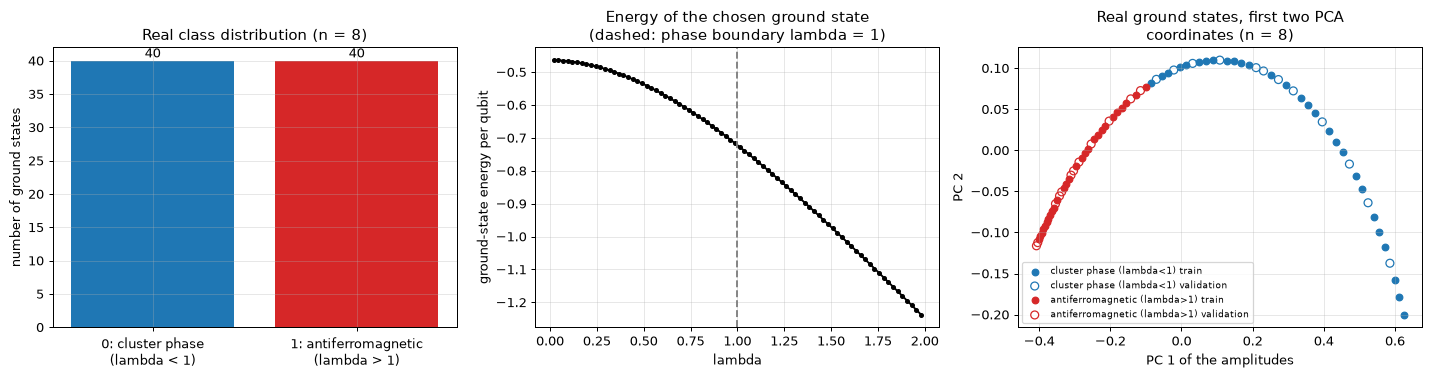

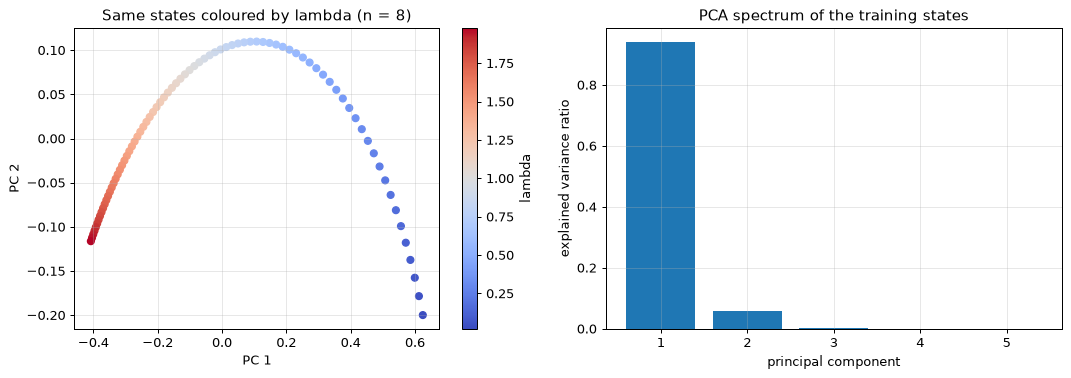

explained variance of the two plotted components: [0.94  0.058]


In [7]:
# ------------------------------------------------------------------ class distribution + energy curve + 2-D map of the real states
fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
cnt = np.bincount(d["y"], minlength=2)
ax[0].bar(["0: cluster phase\n(lambda < 1)", "1: antiferromagnetic\n(lambda > 1)"], cnt, color=["tab:blue", "tab:red"])
for i, c in enumerate(cnt): ax[0].text(i, c + 0.5, str(c), ha="center")
ax[0].set_ylabel("number of ground states"); ax[0].set_title(f"Real class distribution (n = {N_VIS})")

ax[1].plot(d["lam"], d["E"] / N_VIS, "k.-")
ax[1].axvline(1.0, color="gray", ls="--"); ax[1].set_xlabel("lambda"); ax[1].set_ylabel("ground-state energy per qubit")
ax[1].set_title("Energy of the chosen ground state\n(dashed: phase boundary lambda = 1)")

pca5 = PCA(n_components=5, random_state=SEED).fit(d["X"][d["tr"]])         # fitted on the training split only
pca = pca5
Z = pca5.transform(d["X"])[:, :2]
for lab, col, nm in [(0, "tab:blue", "cluster phase (lambda<1)"), (1, "tab:red", "antiferromagnetic (lambda>1)")]:
    m = d["y"] == lab
    ax[2].scatter(Z[m & np.isin(np.arange(len(d["y"])), d["tr"]), 0], Z[m & np.isin(np.arange(len(d["y"])), d["tr"]), 1], c=col, s=28, label=nm + " train")
    ax[2].scatter(Z[m & np.isin(np.arange(len(d["y"])), d["va"]), 0], Z[m & np.isin(np.arange(len(d["y"])), d["va"]), 1], facecolors="none", edgecolors=col, s=40, label=nm + " validation")
ax[2].set_xlabel("PC 1 of the amplitudes"); ax[2].set_ylabel("PC 2"); ax[2].set_title(f"Real ground states, first two PCA\ncoordinates (n = {N_VIS})")
ax[2].legend(fontsize=7)
plt.tight_layout(); plt.show()

# same map coloured by the continuous coupling lambda (the ground truth behind the label)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.3))
sc = ax[0].scatter(Z[:, 0], Z[:, 1], c=d["lam"], cmap="coolwarm", s=30); plt.colorbar(sc, ax=ax[0], label="lambda")
ax[0].set_title(f"Same states coloured by lambda (n = {N_VIS})"); ax[0].set_xlabel("PC 1"); ax[0].set_ylabel("PC 2")
ax[1].bar(np.arange(1, 6), pca5.explained_variance_ratio_)
ax[1].set_xlabel("principal component"); ax[1].set_ylabel("explained variance ratio"); ax[1].set_title("PCA spectrum of the training states")
plt.tight_layout(); plt.show()
print("explained variance of the two plotted components:", np.round(pca5.explained_variance_ratio_[:2], 3))

## 3. Quantum Circuit Architecture

The whole pipeline of Fig. 2(a) is one PennyLane circuit on `n + 1` qubits (wires `0..n-1` carry the data state, wire `n` is the ancilla that is read out):

`StatePrep(psi)  ->  E (encoder)  ->  U(theta) (attacker)  ->  E^dagger (decoder)  ->  V(Theta) (classifier)  ->  <Z> on the ancilla`

* **Layer** (Fig. S1a): `[Z(d)X(c) on every qubit] . CNOT chain . [Z(b)X(a) on every qubit]`, i.e. per qubit four rotations (`RX`, `RZ`, `CNOT` chain, `RX`, `RZ`).
* **Classifier `V`**: `P = 10` layers on `n + 1` qubits, `40 (n + 1)` trainable angles. The ancilla is measured; `Pr(y=0) = (1 + <Z>)/2`, label 0 if `Pr(0) >= Pr(1)`.
* **Adversary `U`**: `L = 4` layers on the `n` data qubits with a CNOT^dagger chain appended to every layer, `16 n` angles, all 0 at the start so that `U = I`.
* **Encoder `E`**: global = 4 layers on the `n` data qubits (`16 n` random angles); local = `n/2` independent two-qubit blocks of 2 layers each.
  The decoder is `E^dagger`, built by reversing the gate list and negating every rotation angle.

Assumptions where the paper is silent (documented in the table above): `RX` before `RZ` inside every Euler unit, CNOT chain from the first to the last qubit,
encoder/decoder use the same layer type as the classifier, random angles uniform in `[0, 2 pi)`.
The drawings below are made from the **tape of the very QNode that is executed** (`qml.workflow.construct_tape`), cut into consecutive pieces so
that they stay readable; a cell asserts that the pieces re-assemble exactly into the executed tape.

In [8]:
# ------------------------------------------------------------------ circuit building blocks (gate lists) and the QNode
def layer_gates(p, W, off=0, undo_ent=False):
    """One layer of Fig. S1(a): [Z(d)X(c) per qubit] . Uent . [Z(b)X(a) per qubit]; p has shape (2, W, 2) = (unit, qubit, (X angle, Z angle)).
    undo_ent=True appends Uent^dagger so that the layer is the identity for all-zero angles (adversary, Appendix B)."""
    g = []
    for q in range(W):                       # CHOICE: Z(theta_u) X(theta_v) = X applied first, then Z
        g += [("RX", (off+q,), p[0, q, 0]), ("RZ", (off+q,), p[0, q, 1])]
    g += [("CNOT", (off+q, off+q+1), None) for q in range(W-1)]                  # Uent: CNOT chain on neighbouring qubits
    for q in range(W):
        g += [("RX", (off+q,), p[1, q, 0]), ("RZ", (off+q,), p[1, q, 1])]
    if undo_ent:
        g += [("CNOT", (off+q, off+q+1), None) for q in reversed(range(W-1))]
    return g

def circuit_gates(params, W, off=0, undo_ent=False):
    g = []
    for l in range(params.shape[0]):
        g += layer_gates(params[l], W, off, undo_ent)
    return g

def local_encoder_gates(params, n):
    """Tensor product of n/2 independent two-qubit blocks; params shape (n//2, layers, 2, 2, 2)."""
    g = []
    for b in range(n // 2):
        g += circuit_gates(params[b], 2, off=2*b)
    return g

def inverse_gates(g):
    return [(nm, w, None if a is None else -a) for nm, w, a in reversed(g)]

def apply_gates(g):
    for name, w, a in g:
        if name == "RX": qml.RX(a, wires=w[0])
        elif name == "RZ": qml.RZ(a, wires=w[0])
        else: qml.CNOT(wires=list(w))

def make_qnode(n, device="lightning.qubit"):
    """Pipeline of Fig. 2(a).  enc: None (no defence) | gate list | 2^n x 2^n unitary matrix.  adv: None | (L,2,n,2).  clf: (P,2,n+1,2)."""
    dev = qml.device(device, wires=n + 1)
    @qml.qnode(dev, diff_method="adjoint" if "lightning" in device else "backprop")
    def f(psi, enc, adv, clf):
        qml.StatePrep(psi, wires=list(range(n)))
        if enc is not None:
            if isinstance(enc, list): apply_gates(enc)
            else: qml.QubitUnitary(enc, wires=list(range(n)))
        if adv is not None:
            apply_gates(circuit_gates(adv, n, undo_ent=True))
        if enc is not None:
            if isinstance(enc, list): apply_gates(inverse_gates(enc))
            else: qml.QubitUnitary(np.conj(enc).T, wires=list(range(n)))
        apply_gates(circuit_gates(clf, n + 1))
        return qml.expval(qml.PauliZ(n))
    return f

QN = {n: make_qnode(n) for n in SIZES}

A. Without defence:  |psi> -> U(theta) -> V(Theta) -> <Z_ancilla>   (all pieces drawn)


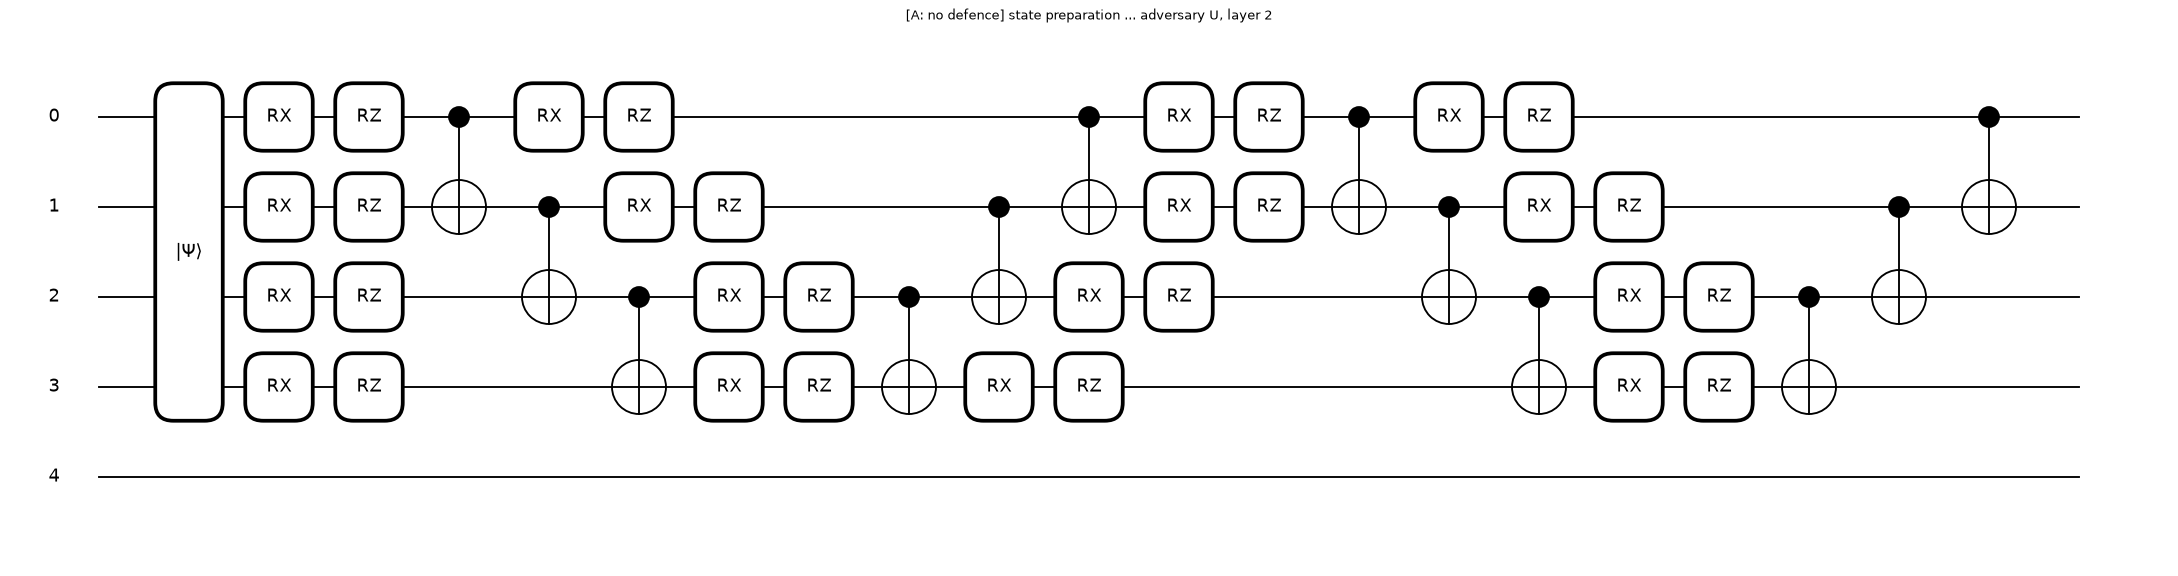

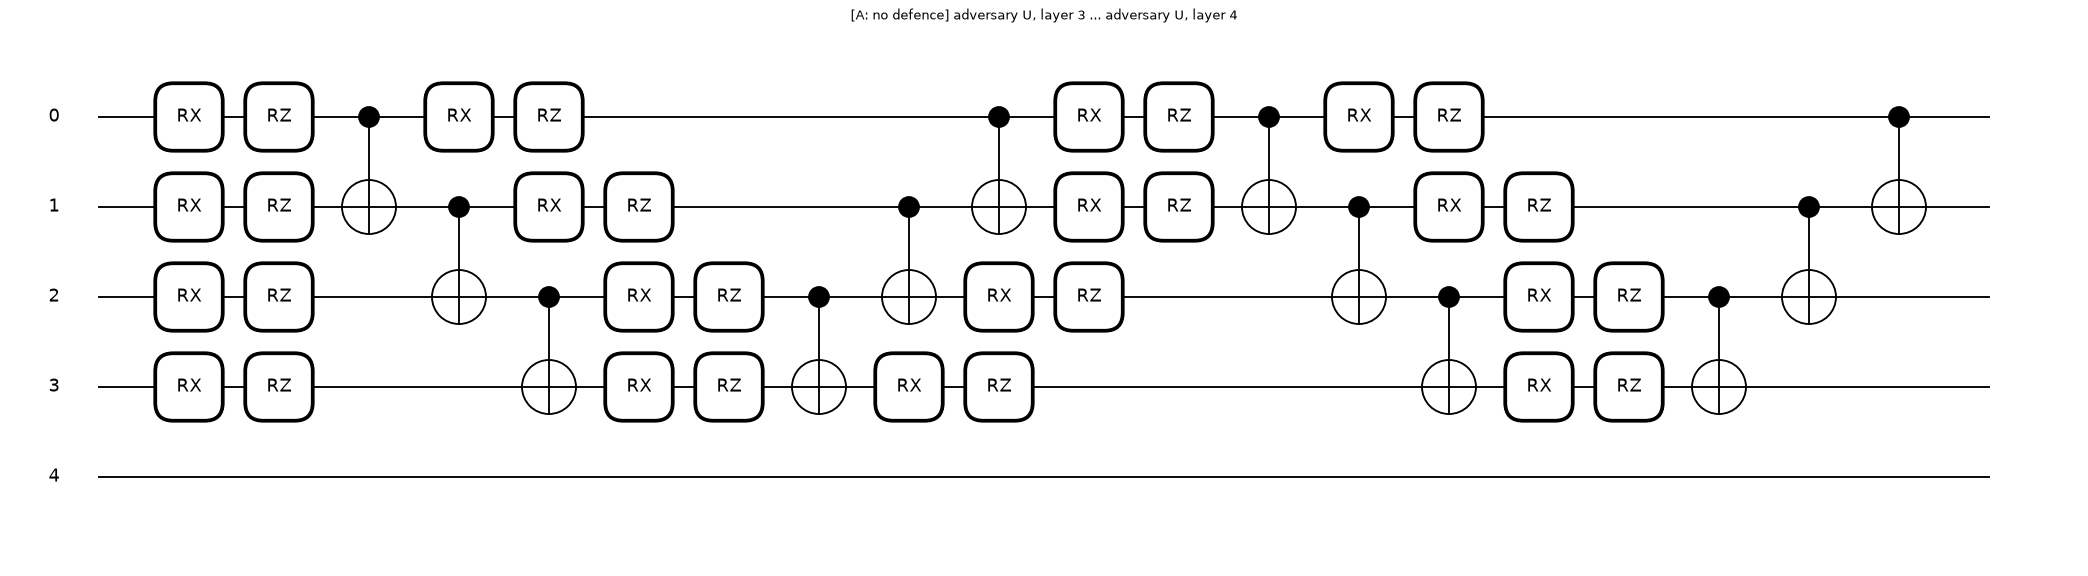

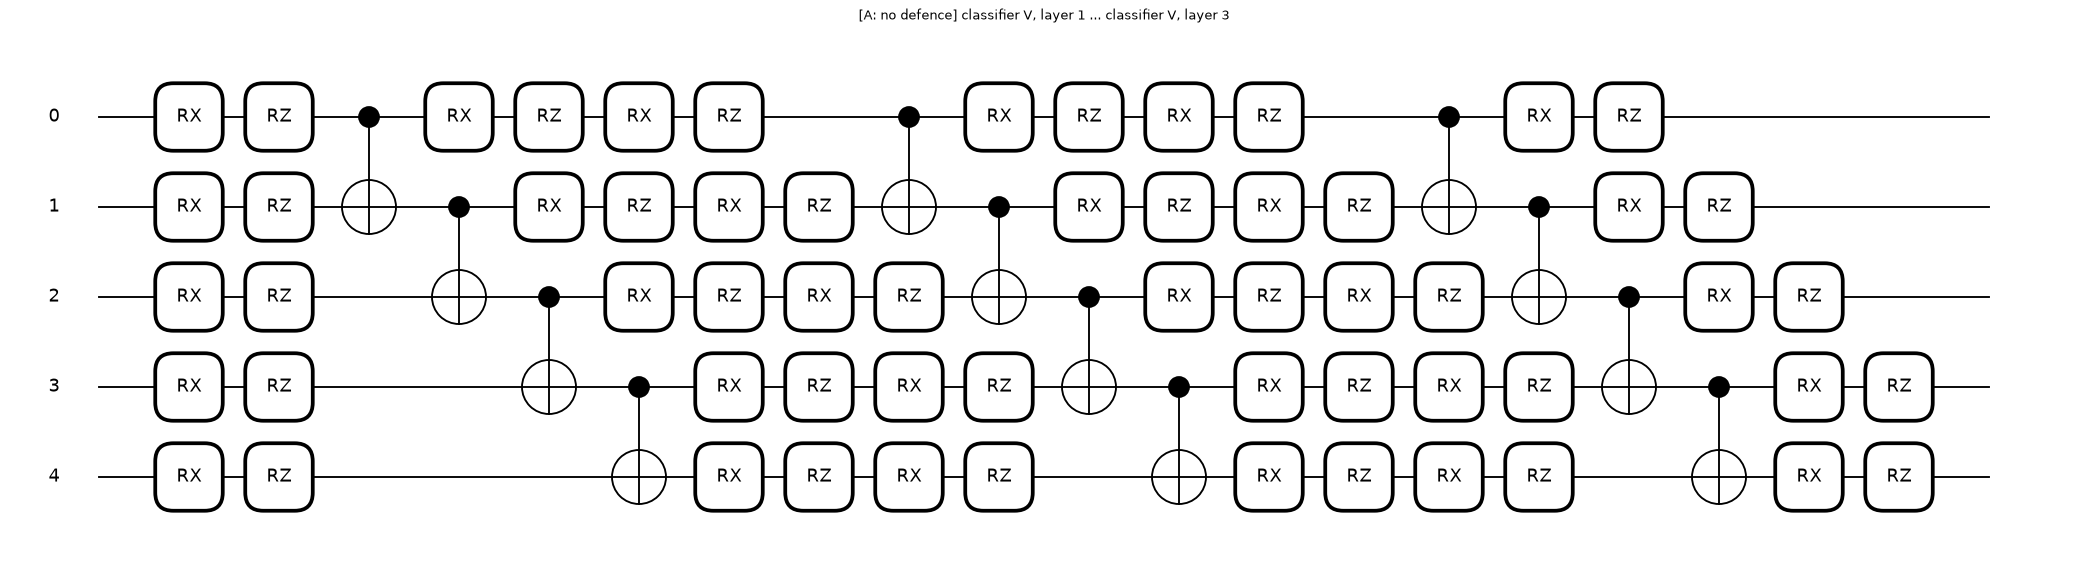

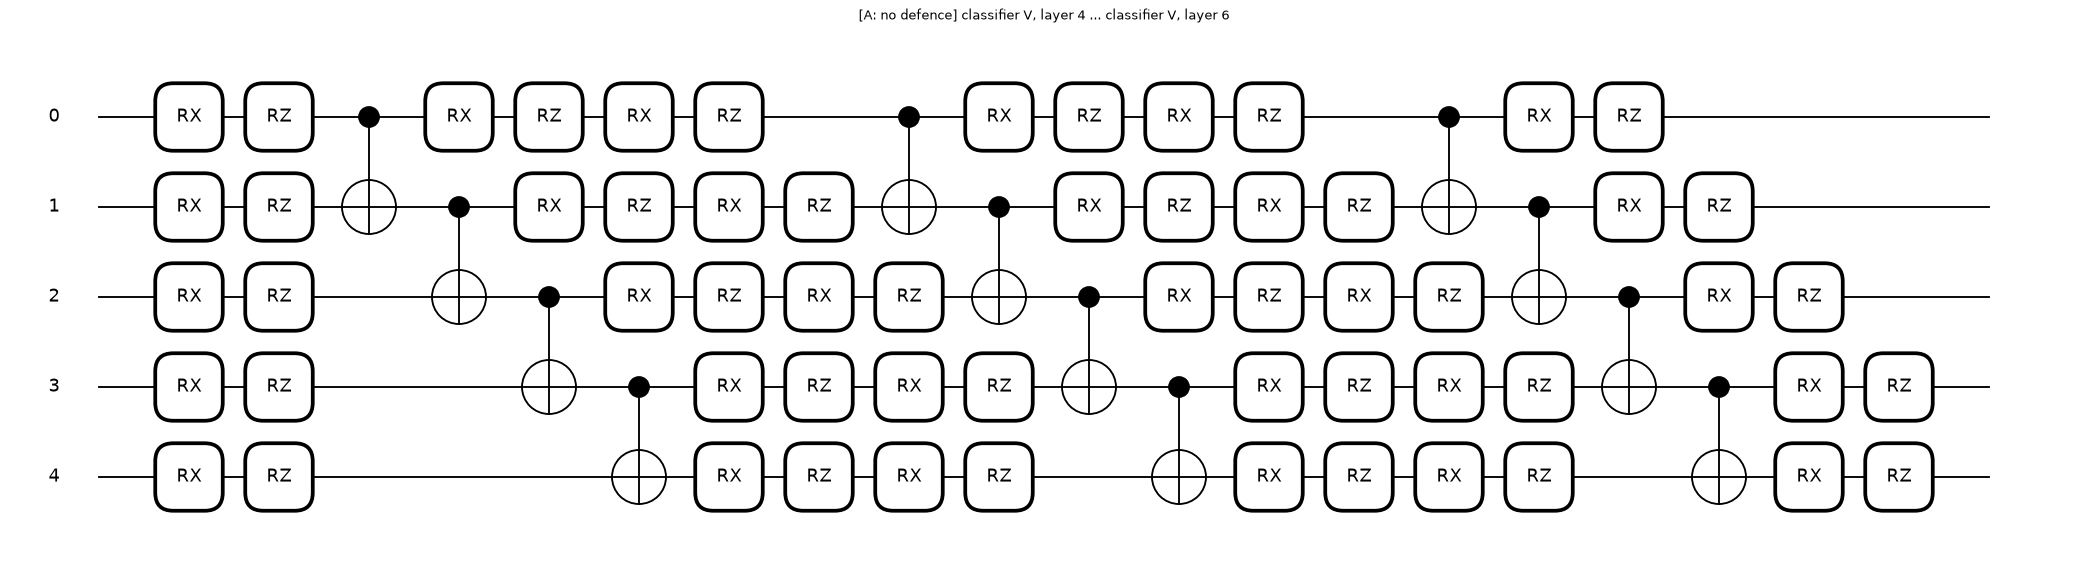

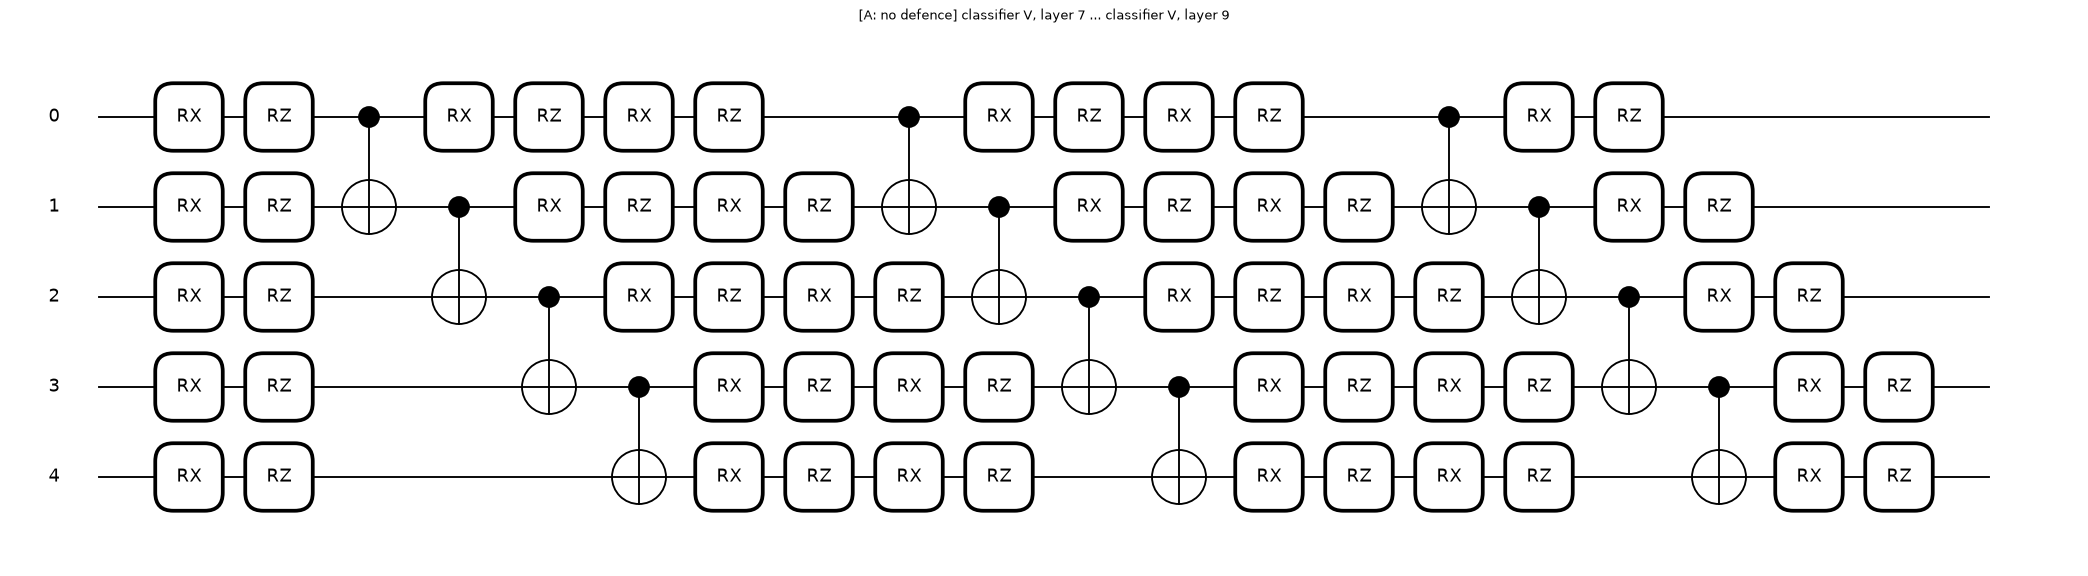

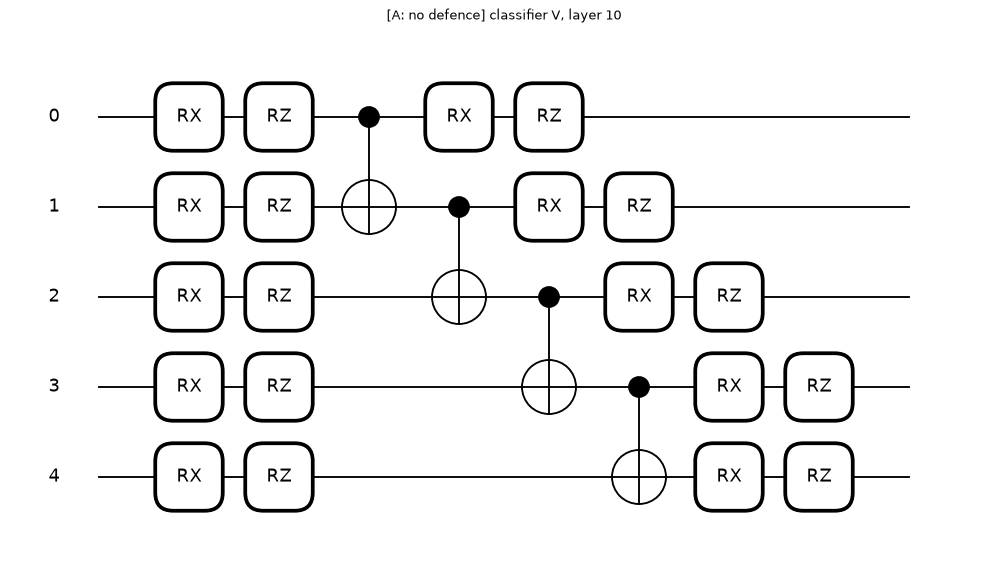

   operations in the executed tape, pieces, pieces drawn: (329, 6, 6)


In [9]:
# ------------------------------------------------------------------ draw the circuit that is executed (n = 4, the smallest size of the study)
from pennylane.tape import QuantumScript
n_d = 4
rd = rng_for(n_d, 99)
psi_d = DATA[n_d]["X"][0] if n_d in DATA else ground_state(n_d, 0.1)[0]
clf_d = rd.uniform(0, 2*np.pi, (P_CLF, 2, n_d + 1, 2))
adv_d = np.zeros((L_ADV, 2, n_d, 2))                                  # theta_0: the attacker starts at the identity
enc_g_d = circuit_gates(rd.uniform(0, 2*np.pi, (L_ENC, 2, n_d, 2)), n_d)
enc_l_d = local_encoder_gates(rd.uniform(0, 2*np.pi, (n_d // 2, L_LOC, 2, 2, 2)), n_d)
f_d = make_qnode(n_d, "default.qubit")

def tape_of(enc):
    return qml.workflow.construct_tape(f_d, level="top")(psi_d, enc, adv_d, clf_d)

def piece_plan(enc, kind):
    """(label, number of operations) of consecutive pieces of the executed tape, in execution order."""
    lay_adv = len(layer_gates(adv_d[0], n_d, undo_ent=True)); lay_clf = len(layer_gates(clf_d[0], n_d + 1))
    plan = [("state preparation", 1)]
    if enc is not None:
        if kind == "global":
            per = len(enc) // L_ENC; plan += [(f"encoder E, layer {k+1}", per) for k in range(L_ENC)]
        else:
            plan += [("encoder E (two 2-qubit blocks)", len(enc))]
    plan += [(f"adversary U, layer {k+1}", lay_adv) for k in range(L_ADV)]
    if enc is not None:
        if kind == "global": plan += [(f"decoder E^dagger, layer {k+1}", per) for k in range(L_ENC)]
        else: plan += [("decoder E^dagger", len(enc))]
    plan += [(f"classifier V, layer {k+1}", lay_clf) for k in range(P_CLF)]
    return plan

def draw_pipeline(enc, kind, tag, only=("state", "encoder", "decoder"), max_cols=24):
    """Cut the executed tape into consecutive pieces, assert that they re-assemble into the tape, and draw the pieces whose label contains a word of `only`
    (None = draw everything)."""
    ops = tape_of(enc).operations; plan = piece_plan(enc, kind)
    assert sum(c for _, c in plan) == len(ops)
    segs, pos = [], 0
    for nm, c in plan:
        segs.append((nm, ops[pos:pos + c])); pos += c
    assert [o for _, s in segs for o in s] == list(ops)               # the pieces re-assemble into the executed tape
    groups, cur, cols = [], [], 0
    for nm, s in segs:
        dp = QuantumScript(s).specs["resources"].depth
        if cur and cols + dp > max_cols: groups.append(cur); cur, cols = [], 0
        cur.append((nm, s)); cols += dp
    if cur: groups.append(cur)
    shown = 0
    for gp in groups:
        if only is not None and not any(w in nm for nm, _ in gp for w in only): continue
        flat = [o for _, s in gp for o in s]
        fig, ax = qml.drawer.tape_mpl(QuantumScript(flat), wire_order=list(range(n_d + 1)), show_all_wires=True, decimals=None)
        fig.set_size_inches(min(fig.get_size_inches()[0], 26), fig.get_size_inches()[1])
        ax.set_title(f"[{tag}] " + gp[0][0] + (" ... " + gp[-1][0] if len(gp) > 1 else ""), fontsize=10)
        plt.show(); shown += 1
    return len(ops), len(groups), shown

print("A. Without defence:  |psi> -> U(theta) -> V(Theta) -> <Z_ancilla>   (all pieces drawn)")
print("   operations in the executed tape, pieces, pieces drawn:", draw_pipeline(None, "none", "A: no defence", only=None))

B. Global random encoder:  |psi> -> E -> U(theta) -> E^dagger -> V(Theta) -> <Z_ancilla>   (state preparation, encoder and decoder drawn; U and V are the pieces of A)


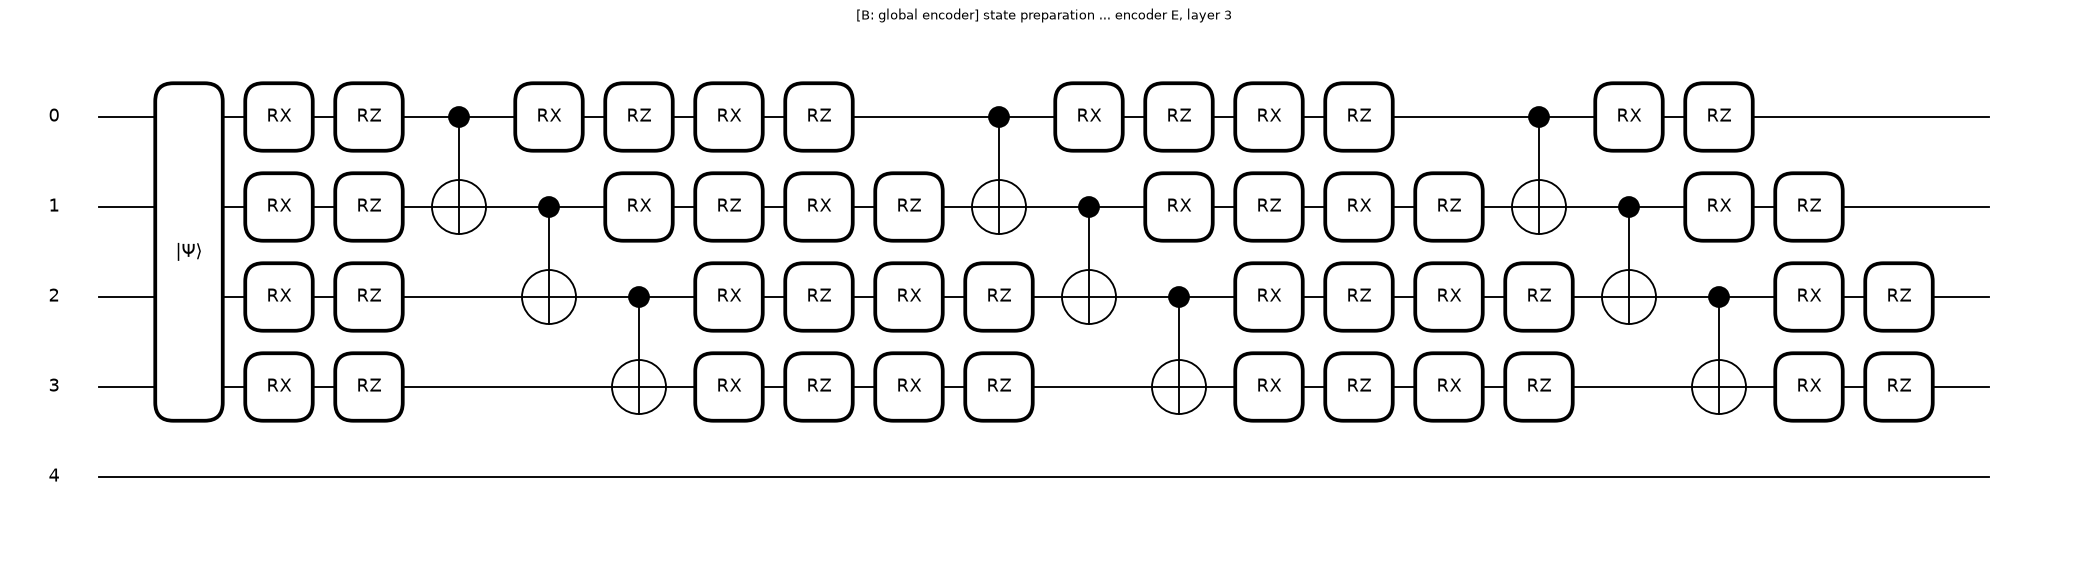

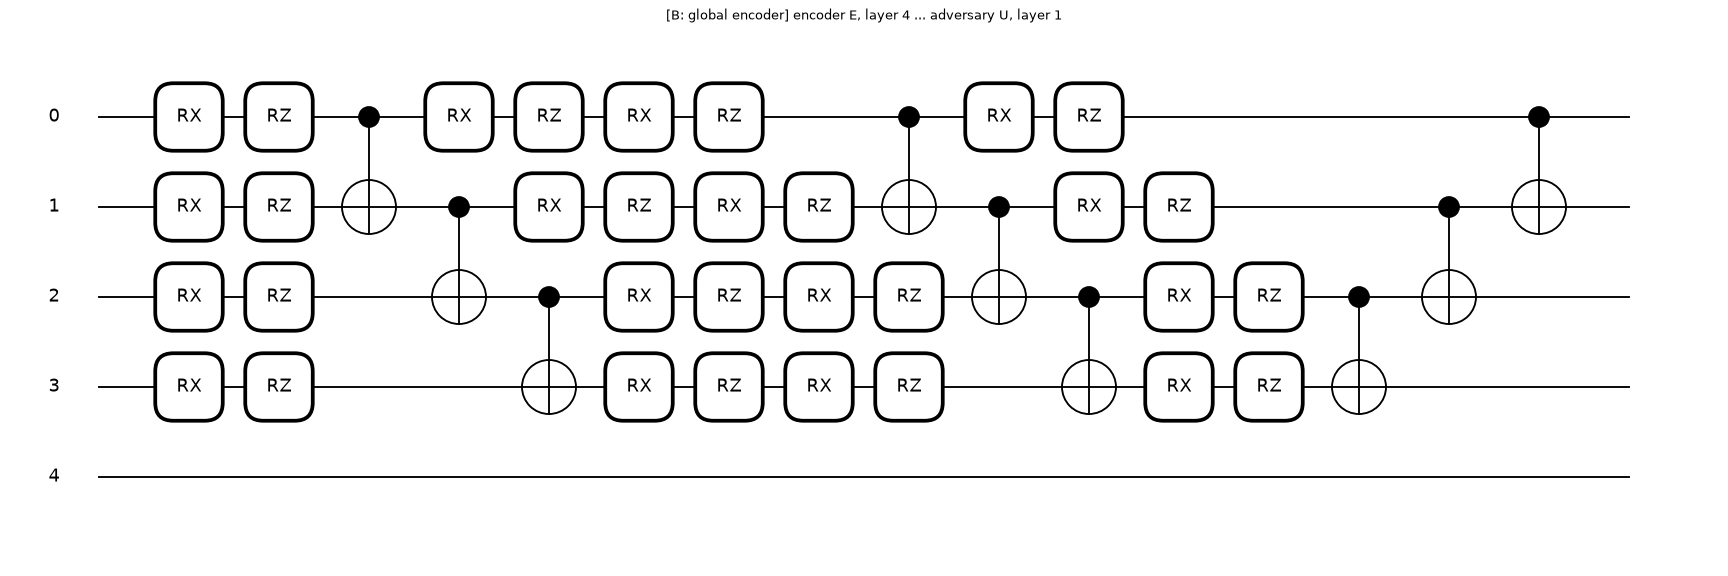

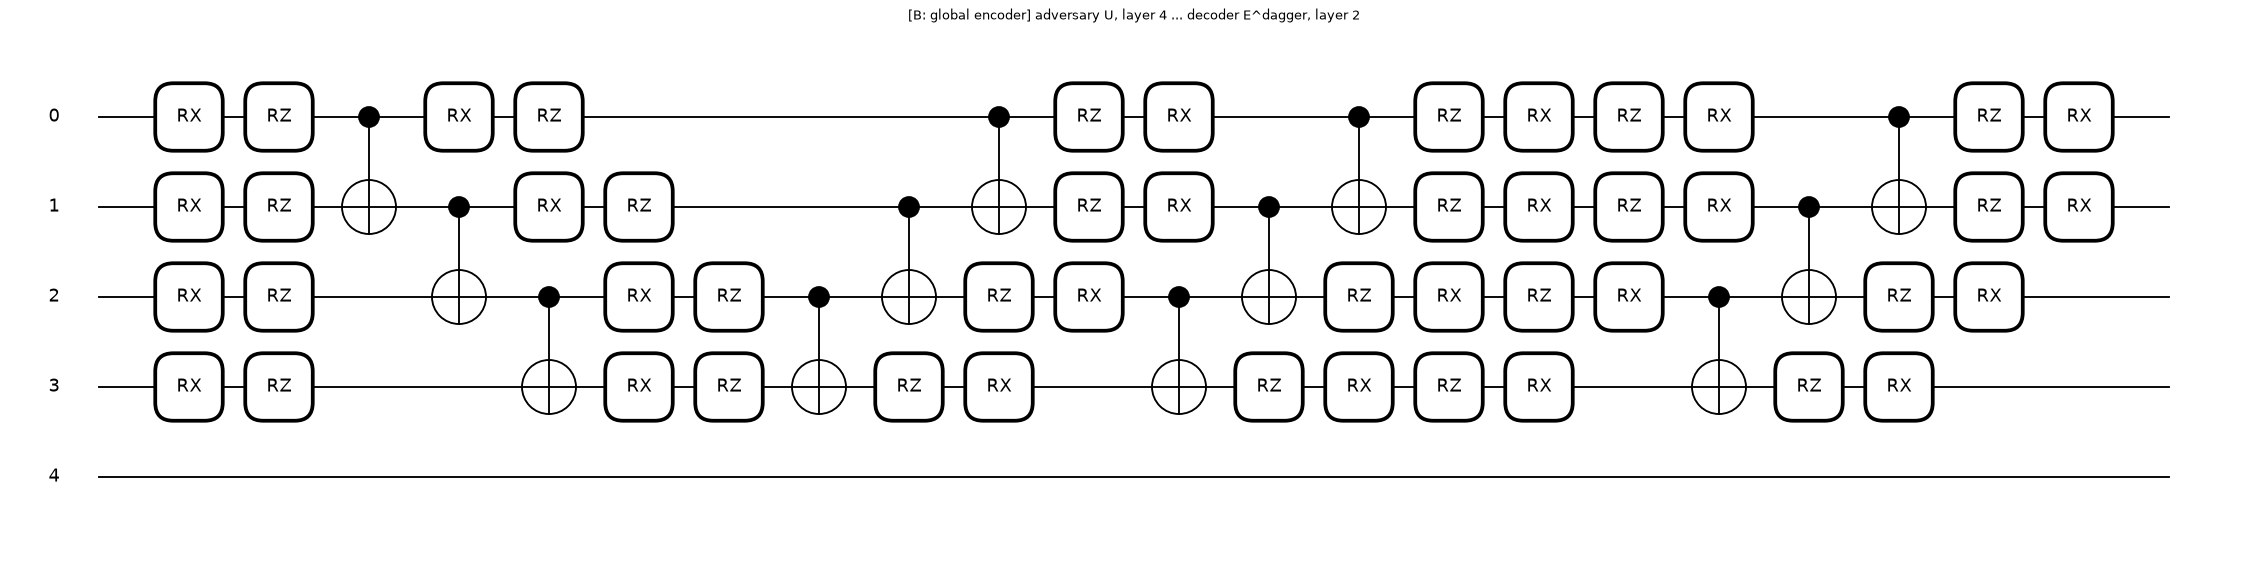

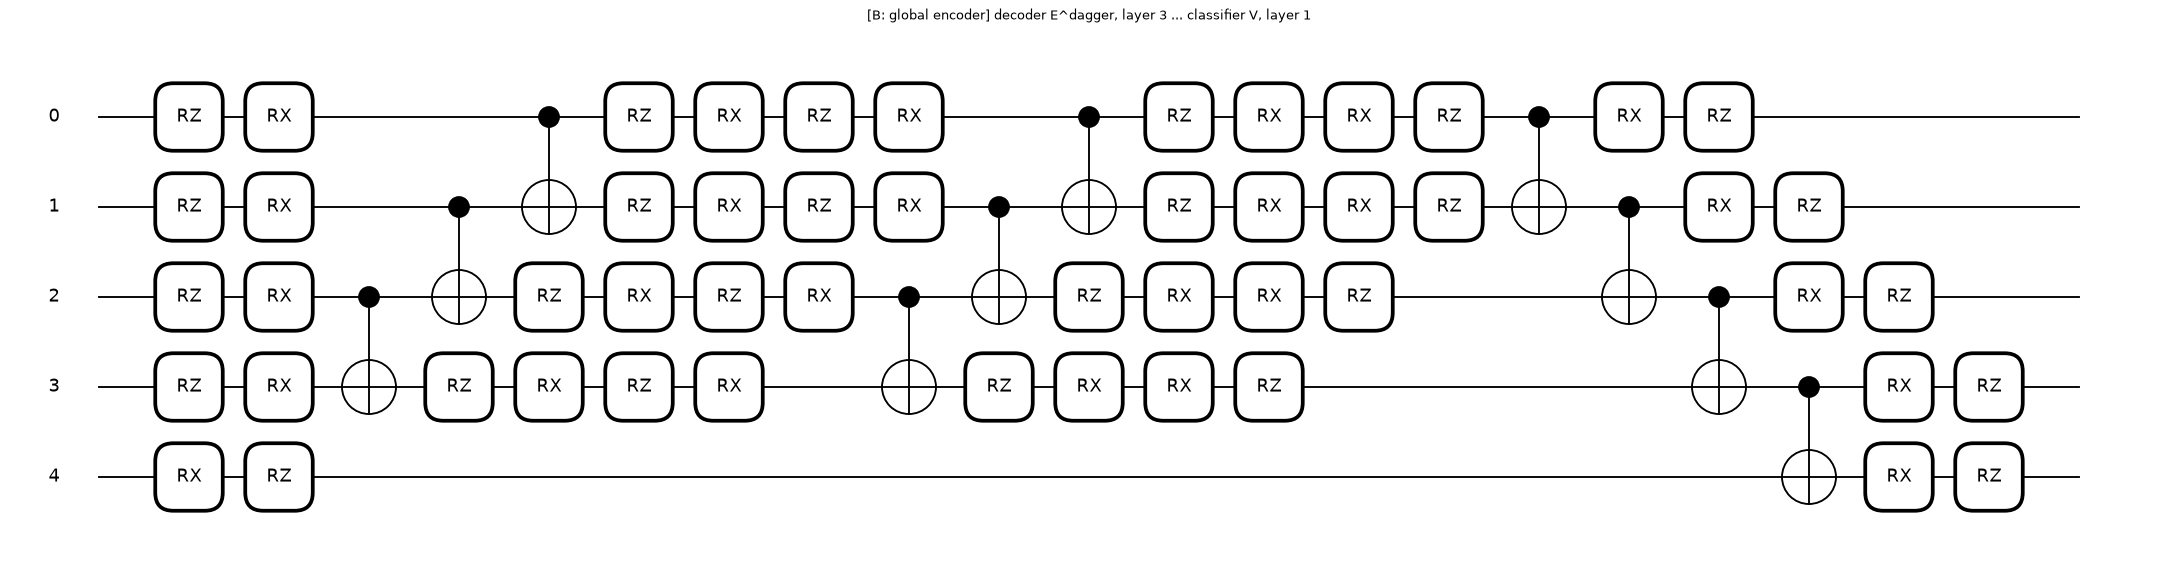

   operations, pieces, pieces drawn: (481, 8, 4)
C. Local random encoder (two 2-qubit blocks)


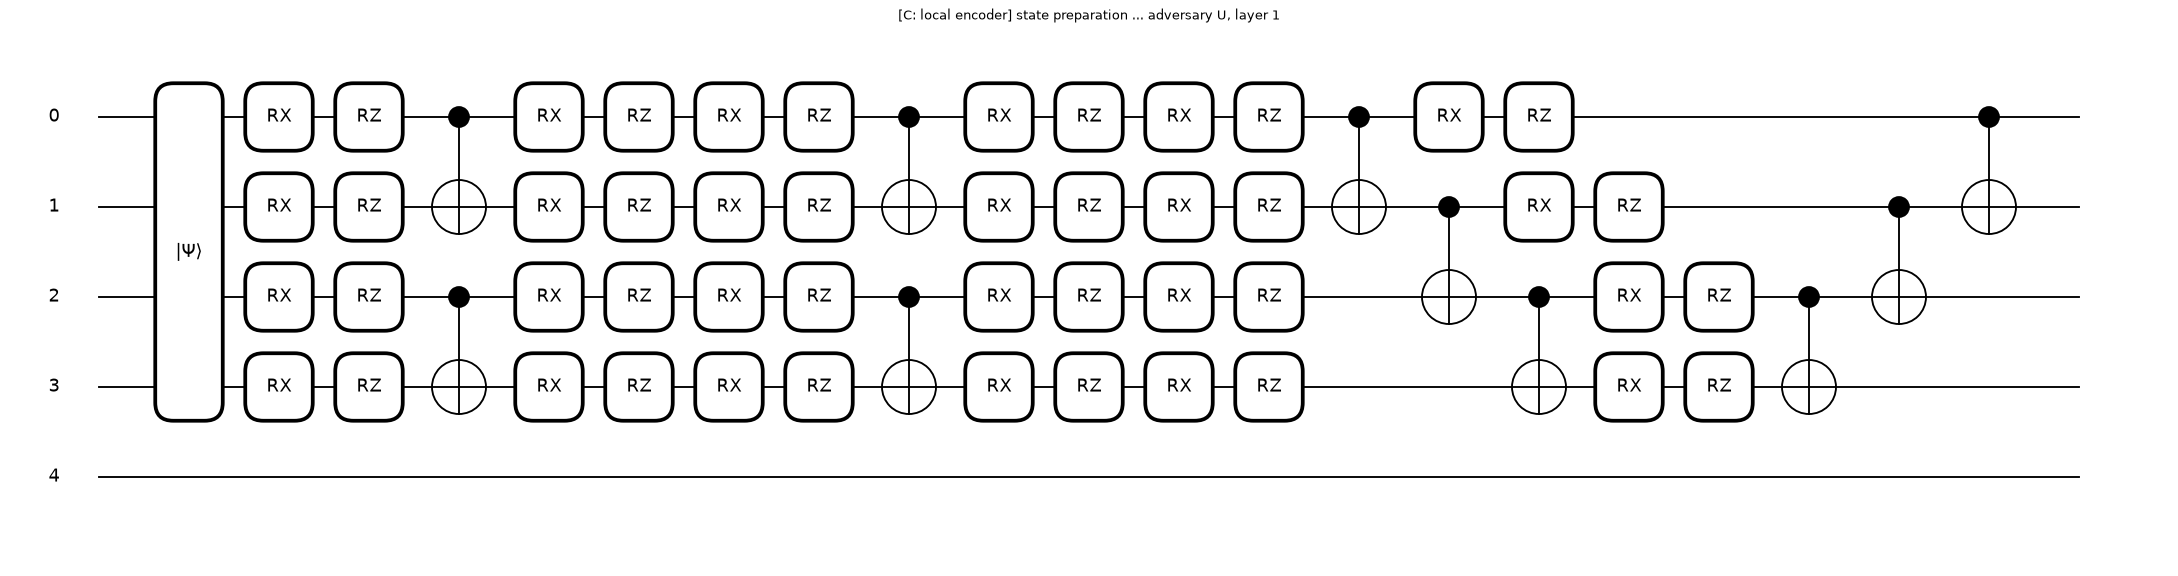

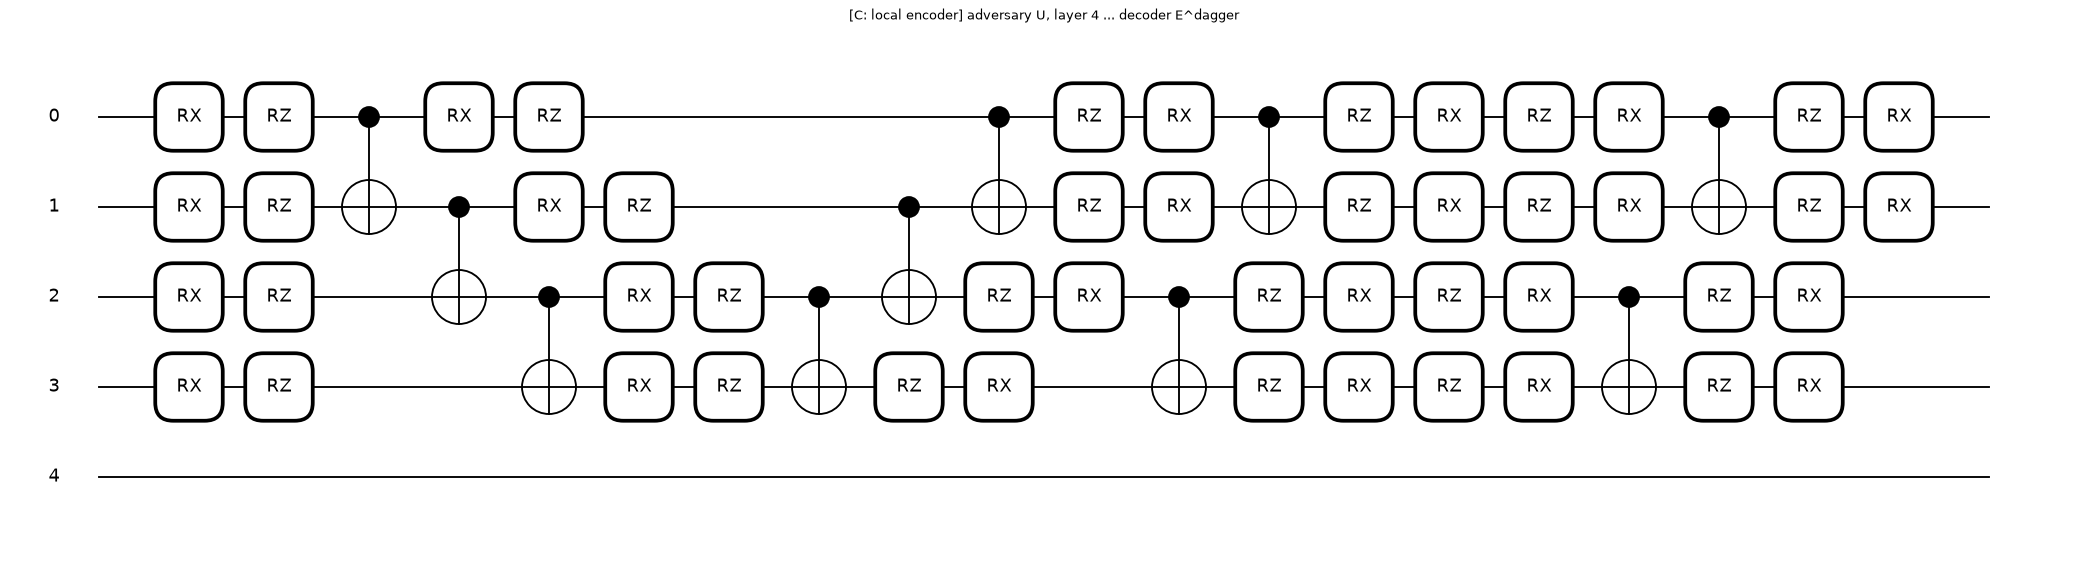

   operations, pieces, pieces drawn: (401, 7, 2)
assertion passed: adversary and classifier operations in B and C are identical to those drawn in A


In [10]:
print("B. Global random encoder:  |psi> -> E -> U(theta) -> E^dagger -> V(Theta) -> <Z_ancilla>   (state preparation, encoder and decoder drawn; U and V are the pieces of A)")
print("   operations, pieces, pieces drawn:", draw_pipeline(enc_g_d, "global", "B: global encoder"))
print("C. Local random encoder (two 2-qubit blocks)")
print("   operations, pieces, pieces drawn:", draw_pipeline(enc_l_d, "local", "C: local encoder"))

# the adversary and classifier pieces of B and C are the pieces drawn for A: assert it on the executed tapes
tA = tape_of(None).operations
for enc in (enc_g_d, enc_l_d):
    tB = tape_of(enc).operations; k = len(enc)
    mid = tB[1 + k:1 + k + len(layer_gates(adv_d[0], n_d, undo_ent=True)) * L_ADV]
    clf_part = tB[1 + 2 * k + len(mid):]
    adv_part_A = tA[1:1 + len(mid)]; clf_part_A = tA[1 + len(mid):]
    same = lambda a, b: len(a) == len(b) and all(x.name == y.name and tuple(x.wires) == tuple(y.wires) and np.allclose(x.parameters, y.parameters) for x, y in zip(a, b))
    assert same(mid, adv_part_A) and same(clf_part, clf_part_A)
print("assertion passed: adversary and classifier operations in B and C are identical to those drawn in A")

In [11]:
# ------------------------------------------------------------------ circuit statistics and equivalence checks
def n_params(arr_shape): return int(np.prod(arr_shape))
rows = []
for lab, enc in [("A no defence", None), ("B global encoder", enc_g_d), ("C local encoder", enc_l_d)]:
    t = tape_of(enc); r = t.specs["resources"]
    n_enc_par = 0 if enc is None else (L_ENC * 2 * n_d * 2 if lab.startswith("B") else (n_d // 2) * L_LOC * 2 * 2 * 2)
    rows.append({"architecture": lab, "qubits": n_d + 1, "depth": r.depth, "gates": int(sum(r.gate_types.values())),
                 "classifier angles": n_params(clf_d.shape), "adversary angles": n_params(adv_d.shape), "encoder angles": n_enc_par})
display(pd.DataFrame(rows))
print("Classifier V: P =", P_CLF, "layers on", n_d + 1, "qubits;  adversary U:", L_ADV, "layers on", n_d, "qubits;  global encoder:", L_ENC, "layers;  local blocks:", L_LOC, "layers x", n_d // 2, "blocks")
print("For general n: classifier angles = 40 (n+1), adversary angles = 16 n, global encoder angles = 16 n.")

# 1) fast simulator = reference simulator
f_l = make_qnode(n_d, "lightning.qubit")
adv_r = rd.uniform(-0.3, 0.3, adv_d.shape)
for enc in [None, enc_g_d, enc_l_d]:
    assert abs(f_l(psi_d, enc, adv_r, clf_d) - f_d(psi_d, enc, adv_r, clf_d)) < 1e-10
print("lightning.qubit == default.qubit to 1e-10 for all three architectures")
# 2) U(theta_0) = identity, and E^dagger E = identity: the defence does not change the clean prediction
base = float(f_l(psi_d, None, None, clf_d))
for enc in [enc_g_d, enc_l_d]:
    assert abs(f_l(psi_d, enc, np.zeros_like(adv_d), clf_d) - base) < 1e-10
    assert abs(f_l(psi_d, enc, None, clf_d) - base) < 1e-10
print("clean output with the encoder == clean output without it (U(theta_0)=I and E^dagger E = I):", round(base, 6))
# 3) Haar-unitary encoder variant of the same QNode gives the same clean output
from scipy.stats import unitary_group
Uh = unitary_group.rvs(2**n_d, random_state=SEED)
assert abs(f_l(psi_d, Uh, np.zeros_like(adv_d), clf_d) - base) < 1e-9
# 4) adjoint gradient == finite difference
adv_t = pnp.array(adv_r, requires_grad=True)
g_adj = qml.grad(lambda a: f_l(psi_d, enc_g_d, a, clf_d))(adv_t)
ix = (1, 0, 2, 1); a2 = adv_r.copy(); a3 = adv_r.copy(); a2[ix] += 1e-6; a3[ix] -= 1e-6
g_fd = (f_l(psi_d, enc_g_d, a2, clf_d) - f_l(psi_d, enc_g_d, a3, clf_d)) / 2e-6
assert abs(g_adj[ix] - g_fd) < 1e-6
print("adjoint gradient == finite difference:", float(g_adj[ix]), float(g_fd))

# 5) the batched NumPy simulator used to train the classifier (Section 4) is the same circuit: values and gradients equal the QNode
class BatchSim:
    """Exact batched state-vector simulator for the gate set {RX, RZ, CNOT} (wire 0 = most significant bit, like PennyLane) with a hand-written
    adjoint gradient. It runs exactly the gate list of `circuit_gates`; it is used only to train the classifier on mini-batches quickly."""
    def __init__(self, nq):
        self.nq = nq; self.N = 1 << nq; idx = np.arange(self.N)
        self.bit = [((idx >> (nq - 1 - w)) & 1) for w in range(nq)]
        self.sgn = [1 - 2.0 * b for b in self.bit]
        self.cperm = {}
    def cnot_perm(self, c, t):
        if (c, t) not in self.cperm:
            self.cperm[(c, t)] = np.arange(self.N) ^ (self.bit[c] << (self.nq - 1 - t))
        return self.cperm[(c, t)]
    def flip_perm(self, w):
        if ("x", w) not in self.cperm:
            self.cperm[("x", w)] = np.arange(self.N) ^ (1 << (self.nq - 1 - w))
        return self.cperm[("x", w)]
    def rot(self, psi, kind, w, ang):
        B = psi.shape[0]; v = psi.reshape(B, 1 << w, 2, 1 << (self.nq - w - 1)); a, b = v[:, :, 0], v[:, :, 1]
        c, s = np.cos(ang / 2), np.sin(ang / 2); out = np.empty_like(v)
        if kind == "RX":
            out[:, :, 0] = c * a - 1j * s * b; out[:, :, 1] = -1j * s * a + c * b
        else:
            out[:, :, 0] = (c - 1j * s) * a; out[:, :, 1] = (c + 1j * s) * b
        return out.reshape(B, self.N)
    def run(self, psi, ops, theta):
        for kind, w, ix in ops:
            psi = psi[:, self.cnot_perm(*w)] if kind == "CNOT" else self.rot(psi, kind, w[0], theta[ix])
        return psi
    def z_anc(self, psi):
        return (np.abs(psi) ** 2) @ self.sgn[self.nq - 1]
    def value_and_grad(self, psi0, ops, theta, dL_dz):
        """<Z_ancilla> of every state and the gradient of L = sum_b dL_dz[b] * z_b w.r.t. theta (adjoint method, no autodiff)."""
        psi = self.run(psi0, ops, theta); z = self.z_anc(psi)
        lam = (dL_dz[:, None] * self.sgn[self.nq - 1][None, :]) * psi
        g = np.zeros_like(theta)
        for kind, w, ix in reversed(ops):
            if kind == "CNOT":
                p = self.cnot_perm(*w); psi = psi[:, p]; lam = lam[:, p]; continue
            Ppsi = psi[:, self.flip_perm(w[0])] if kind == "RX" else psi * self.sgn[w[0]][None, :]
            g[ix] += np.real(np.sum(np.conj(lam) * (-1j) * Ppsi))          # 2 Re <lam| (-i P/2) |psi>
            psi = self.rot(psi, kind, w[0], -theta[ix]); lam = self.rot(lam, kind, w[0], -theta[ix])
        return z, g

def clf_ops(n, P):
    """Classifier gate list with indices into the flattened parameter array."""
    shape = (P, 2, n + 1, 2); ix = np.arange(int(np.prod(shape))).reshape(shape)
    return [(nm, w, None if a is None else int(a)) for nm, w, a in circuit_gates(ix, n + 1)]

def embed_state(psis, n):
    out = np.zeros((psis.shape[0], 2 ** (n + 1)), dtype=complex); out[:, ::2] = psis       # |psi> (x) |0_ancilla>, ancilla = last wire
    return out

psis_t = np.stack([psi_d, ground_state(n_d, 1.5)[0]]); w_t = np.array([0.7, -1.3])
sim_t = BatchSim(n_d + 1)
z_b, g_b = sim_t.value_and_grad(embed_state(psis_t, n_d), clf_ops(n_d, P_CLF), clf_d.ravel(), w_t)
z_q = np.array([float(f_l(p, None, None, clf_d)) for p in psis_t])
c_t = pnp.array(clf_d, requires_grad=True)
g_q = np.asarray(qml.grad(lambda cc: w_t[0] * f_l(psis_t[0], None, None, cc) + w_t[1] * f_l(psis_t[1], None, None, cc))(c_t)).ravel()
assert np.allclose(z_b, z_q, atol=1e-10) and np.allclose(g_b, g_q, atol=1e-9)
print("BatchSim == QNode: output difference", float(np.abs(z_b - z_q).max()), "| classifier-gradient difference", float(np.abs(g_b - g_q).max()))

,architecture,qubits,depth,gates,classifier angles,adversary angles,encoder angles
0,A no defence,5,103,329,200,64,0
1,B global encoder,5,151,481,200,64,64
2,C local encoder,5,123,401,200,64,32


Classifier V: P = 10 layers on 5 qubits;  adversary U: 4 layers on 4 qubits;  global encoder: 4 layers;  local blocks: 2 layers x 2 blocks
For general n: classifier angles = 40 (n+1), adversary angles = 16 n, global encoder angles = 16 n.


lightning.qubit == default.qubit to 1e-10 for all three architectures


clean output with the encoder == clean output without it (U(theta_0)=I and E^dagger E = I): -0.096678


adjoint gradient == finite difference: 0.2812654681219299 0.28126546831874766


BatchSim == QNode: output difference 6.938893903907228e-17 | classifier-gradient difference 9.159339953157541e-16


## 4. Training the 10-layer classifier (Fig. S1)

The classifier `V(Theta)` is trained on the training split of each system size (Adam; exact adjoint gradients instead of the paper's finite differences).
The loss is the **normalised square loss** `1 - |<y|rho_out|y>|^2 = 1 - Pr(y)^2` (training with the KL divergence is repeated at the size used for the
training-curve figure). A random 10-layer circuit on up to 15 qubits sits on a barren plateau, and in our runs plain gradient descent from a random start mostly finds constant predictors (the square loss can be lowered by making the output more confident without improving the accuracy). Our `# CHOICE:` is therefore to draw `K` random
parameter sets, rank them by training accuracy (ties by training loss; forward passes only), then run Adam from the best one and keep the best iterate under the same training ranking. One "epoch" in the plots is 10 iterations, as in Fig. S1; the curves show the *current* Adam iterate, so they can show the loss falling while the accuracy does not improve - exactly the effect described above.

Because the interesting object of the paper is the *attacker's* gradient, the classifier only has to be a reasonable, trained `V`; its accuracy at each size is
reported honestly below (the two phases have nearly identical ground states close to `lambda = 1`, so a perfect score is impossible there).

In [12]:
# ------------------------------------------------------------------ training (batched NumPy simulator verified against the QNode in Section 3)
CLF, CLF_SH, HIST, TRAIN_INFO, TRAIN_SH_INFO = {}, {}, {}, [], []
SIMS = {n: BatchSim(n + 1) for n in SIZES}
OPS = {(n, P): clf_ops(n, P) for n in SIZES for P in (P_CLF, P_SH)}
P0 = {n: embed_state(DATA[n]["X"], n) for n in SIZES}

def z_of(n, c, ids):
    """<Z_ancilla> of the classifier for the states `ids` (no encoder, no adversary)."""
    ids = np.asarray(list(ids)); step = 32 if n <= 10 else 8; th = np.asarray(c).ravel(); ops = OPS[(n, th.size // (4 * (n + 1)))]
    return np.concatenate([SIMS[n].z_anc(SIMS[n].run(P0[n][ids[s:s + step]], ops, th)) for s in range(0, len(ids), step)])

def p_correct(z, y):
    return np.where(y == 0, (1 + z) / 2, (1 - z) / 2)          # Pr(ancilla = y)

def loss_value(z, y, kind):
    p = p_correct(z, y)
    return float(np.mean(1 - p**2) if kind == "NS" else np.mean(-np.log(p + 1e-9)))

def acc_value(z, y):
    return float(np.mean((z < 0).astype(int) == y))              # label 1 if Pr(1) > Pr(0)  <=>  <Z> < 0

def train_classifier(n, kind, iters, K, rng, P=None):
    P = P_CLF if P is None else P
    d = DATA[n]; y, tr, va = d["y"], d["tr"], d["va"]
    sel = tr[:min(len(tr), SEL_STATES[n])]                        # training states used to rank candidates (never validation states)
    tr_e, va_e = tr[:min(len(tr), 24)], va[:min(len(va), 24)]
    score = lambda th: (lambda z: (acc_value(z, y[sel]), -loss_value(z, y[sel], kind)))(z_of(n, th, sel))
    # CHOICE: best of K random initialisations, ranked by (training accuracy, -training loss). A random 10-layer circuit already
    # contains good read-outs; plain gradient descent from a random start sits on a barren plateau and mostly finds constant predictors.
    best = None
    for _ in range(K):
        th = rng.uniform(0, 2 * np.pi, P * 2 * (n + 1) * 2); sc = score(th)
        if best is None or sc > best[0]: best = (sc, th)
    th = best[1].copy(); keep = best                                # keep = best iterate so far on the training ranking
    m = np.zeros_like(th); v = np.zeros_like(th)                    # Adam state (beta1 = 0.9, beta2 = 0.999)
    hist = []
    def record(it):
        ztr, zva = z_of(n, th, tr_e), z_of(n, th, va_e)
        hist.append(dict(iteration=it, train_loss=loss_value(ztr, y[tr_e], kind), val_loss=loss_value(zva, y[va_e], kind),
                         train_acc=acc_value(ztr, y[tr_e]), val_acc=acc_value(zva, y[va_e])))
    for it in range(iters + 1):
        if it % EPOCH_ITERS == 0 or it == iters:
            record(it)
            sc = score(th)
            if sc > keep[0]: keep = (sc, th.copy())
        if it == iters: break
        ids = rng.choice(tr, min(BATCH, len(tr)), replace=False); yy = y[ids]; s = np.where(yy == 0, 1.0, -1.0)
        z0 = z_of(n, th, ids); p = np.clip(p_correct(z0, yy), 1e-6, None)
        dz = (-p * s if kind == "NS" else -(s / 2) / p) / len(ids)        # dL/dz for the mean loss over the mini-batch
        _, g = SIMS[n].value_and_grad(P0[n][ids], OPS[(n, P)], th, dz)
        m = 0.9 * m + 0.1 * g; v = 0.999 * v + 0.001 * g * g
        th = th - LR * (m / (1 - 0.9 ** (it + 1))) / (np.sqrt(v / (1 - 0.999 ** (it + 1))) + 1e-8)
    return keep[1].reshape(P, 2, n + 1, 2), hist, best[0]

t_all = time.time()
for n in SIZES:
    d = DATA[n]
    for kind in (["NS", "KL"] if n == N_FIG else ["NS"]):
        t0 = time.time()
        c, h, sc0 = train_classifier(n, kind, TRAIN_ITERS[n], TRAIN_K[n], rng_for(n, 1 if kind == "NS" else 2))
        ztr, zva = z_of(n, c, d["tr"]), z_of(n, c, d["va"])
        HIST[(n, kind)] = h
        if kind == "NS": CLF[n] = c
        TRAIN_INFO.append({"n": n, "loss": kind, "random starts K": TRAIN_K[n], "Adam iterations": TRAIN_ITERS[n], "train acc": acc_value(ztr, d["y"][d["tr"]]), "validation acc": acc_value(zva, d["y"][d["va"]]),
                           "train loss": loss_value(ztr, d["y"][d["tr"]], kind), "validation loss": loss_value(zva, d["y"][d["va"]], kind), "seconds": round(time.time() - t0, 1)})
        print(TRAIN_INFO[-1], flush=True)
# shallow classifier (P = P_SH layers) used as a control in Section 5
for n in SIZES:
    d = DATA[n]; t0 = time.time()
    c, h, _ = train_classifier(n, "NS", TRAIN_ITERS[n] // 2, max(TRAIN_K[n] // 2, 4), rng_for(n, 3), P=P_SH)
    CLF_SH[n] = c; ztr, zva = z_of(n, c, d["tr"]), z_of(n, c, d["va"])
    TRAIN_SH_INFO.append({"n": n, "layers": P_SH, "train acc": acc_value(ztr, d["y"][d["tr"]]), "validation acc": acc_value(zva, d["y"][d["va"]]), "seconds": round(time.time() - t0, 1)})
TRAIN_SH_DF = pd.DataFrame(TRAIN_SH_INFO); print("shallow classifiers:"); print(TRAIN_SH_DF.round(3).to_string())
TRAIN_DF = pd.DataFrame(TRAIN_INFO)
display(TRAIN_DF.round(3))
print(f"total training time {time.time() - t_all:.0f}s")
# the stored classifier gives the same numbers through the PennyLane QNode (sanity check on the stored parameters)
n0 = SIZES[0]; i0 = DATA[n0]["va"][0]
assert abs(float(QN[n0](DATA[n0]["X"][i0], None, None, CLF[n0])) - z_of(n0, CLF[n0], [i0])[0]) < 1e-9

{'n': 4, 'loss': 'NS', 'random starts K': 150, 'Adam iterations': 20, 'train acc': 0.8928571428571429, 'validation acc': 0.875, 'train loss': 0.6592231085826893, 'validation loss': 0.6621120501725073, 'seconds': 14.9}


{'n': 6, 'loss': 'NS', 'random starts K': 150, 'Adam iterations': 20, 'train acc': 0.9821428571428571, 'validation acc': 1.0, 'train loss': 0.7407201827629424, 'validation loss': 0.7406398442618061, 'seconds': 29.4}


{'n': 6, 'loss': 'KL', 'random starts K': 150, 'Adam iterations': 20, 'train acc': 0.9821428571428571, 'validation acc': 0.9583333333333334, 'train loss': 0.5792492298790629, 'validation loss': 0.5870237318481287, 'seconds': 31.0}


{'n': 8, 'loss': 'NS', 'random starts K': 150, 'Adam iterations': 20, 'train acc': 1.0, 'validation acc': 1.0, 'train loss': 0.7395446659543481, 'validation loss': 0.7397521398024519, 'seconds': 75.5}


shallow classifiers:
   n  layers  train acc  validation acc  seconds
0  4       2      0.964           0.917      1.7
1  6       2      1.000           1.000      2.9
2  8       2      0.982           1.000      6.1


,n,loss,random starts K,Adam iterations,train acc,validation acc,train loss,validation loss,seconds
0,4,NS,150,20,0.893,0.875,0.659,0.662,14.9
1,6,NS,150,20,0.982,1.000,0.741,0.741,29.4
2,6,KL,150,20,0.982,0.958,0.579,0.587,31.0
3,8,NS,150,20,1.000,1.000,0.740,0.740,75.5


total training time 162s


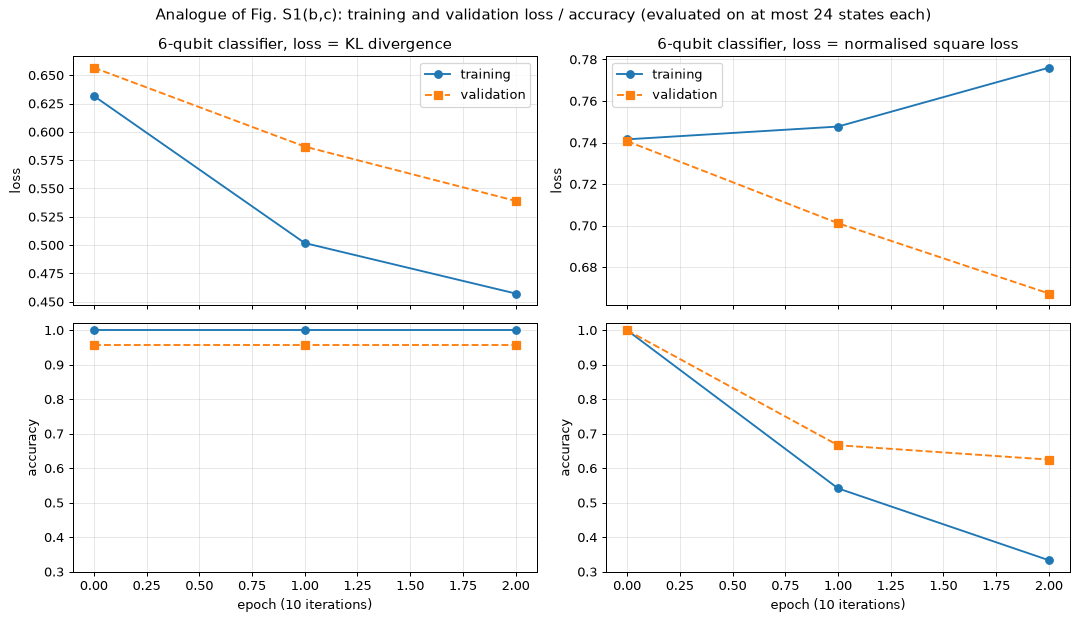

In [13]:
# ------------------------------------------------------------------ Fig. S1 analogue: loss and accuracy of the classifier during training
fig, ax = plt.subplots(2, 2, figsize=(12, 7), sharex="col")
for col, kind in enumerate(["KL", "NS"]):
    h = pd.DataFrame(HIST[(N_FIG, kind)]); ep = h["iteration"] / EPOCH_ITERS
    ax[0, col].plot(ep, h["train_loss"], "o-", label="training"); ax[0, col].plot(ep, h["val_loss"], "s--", label="validation")
    ax[0, col].set_ylabel("loss"); ax[0, col].set_title(f"{N_FIG}-qubit classifier, loss = {'KL divergence' if kind == 'KL' else 'normalised square loss'}"); ax[0, col].legend()
    ax[1, col].plot(ep, h["train_acc"], "o-", label="training"); ax[1, col].plot(ep, h["val_acc"], "s--", label="validation")
    ax[1, col].set_ylabel("accuracy"); ax[1, col].set_xlabel("epoch (10 iterations)"); ax[1, col].set_ylim(0.3, 1.02)
plt.suptitle("Analogue of Fig. S1(b,c): training and validation loss / accuracy (evaluated on at most 24 states each)")
plt.tight_layout(); plt.show()

### Classical baselines on exactly the same inputs

A support-vector machine (RBF kernel) and a random forest are trained on the same ground-state amplitude vectors (all `2^n` features) and the same split, so the
quantum classifier's accuracy can be put in context.

In [14]:
BASE = []
for n in SIZES:
    d = DATA[n]; Xtr, ytr, Xva, yva = d["X"][d["tr"]], d["y"][d["tr"]], d["X"][d["va"]], d["y"][d["va"]]
    svc = SVC(kernel="rbf", C=10.0, gamma="scale").fit(Xtr, ytr)                    # CHOICE: C = 10
    rf = RandomForestClassifier(n_estimators=300, random_state=SEED).fit(Xtr, ytr)
    v = TRAIN_DF[(TRAIN_DF["n"] == n) & (TRAIN_DF["loss"] == "NS")].iloc[0]
    BASE.append({"n": n, "VQC train": v["train acc"], "VQC validation": v["validation acc"], "SVC-RBF train": svc.score(Xtr, ytr), "SVC-RBF validation": svc.score(Xva, yva),
                 "RandomForest train": rf.score(Xtr, ytr), "RandomForest validation": rf.score(Xva, yva)})
BASE_DF = pd.DataFrame(BASE); display(BASE_DF.round(3))

,n,VQC train,VQC validation,SVC-RBF train,SVC-RBF validation,RandomForest train,RandomForest validation
0,4,0.893,0.875,0.982,1.0,1.0,1.0
1,6,0.982,1.000,0.982,1.0,1.0,1.0
2,8,1.000,1.000,0.982,1.0,1.0,1.0


## 5. The attacker's gradient with and without the random encoder (Fig. 3, Theorems 1 and 2)

For every size `n` we draw `N` samples; one sample is a random ground state `|psi>` (with its label `y`) and, when a defence is used, a **fresh random encoder**
(parameters uniform in `[0, 2 pi)`). We then differentiate the classifier's loss with respect to the `16 n` angles of the adversarial circuit `U(theta)` **at `theta = 0`**,
i.e. exactly where a gradient attack starts, and record the gradient vector. The three losses are obtained from the single number `dz = d<Z_ancilla>/d theta`:
with `p = Pr(correct label) = (1 + s z)/2`, `s = +1` for `y = 0` and `-1` for `y = 1`: `dp = s dz / 2`, `dL_NS = -2 p dp`, `dL_KL = -dp / p`, and the plain expectation loss `L = <Z>` (the loss of Theorem 1) has gradient `dz`.

* **none**: no encoder (control, not in the paper): the attacker sees the true gradient.
* **global**: encoder = random 4-layer circuit on all `n` qubits (Theorem 1).
* **local**: encoder = tensor product of random 2-qubit, 2-layer blocks (Theorem 2, `m = 2`).

In [15]:
def sample_encoder(kind, n, rng):
    if kind == "none": return None
    if kind == "global": return circuit_gates(rng.uniform(0, 2 * np.pi, (L_ENC, 2, n, 2)), n)
    return local_encoder_gates(rng.uniform(0, 2 * np.pi, (n // 2, L_LOC, 2, 2, 2)), n)

def adv_gradient(n, i, enc, clf=None):
    clf = CLF[n] if clf is None else clf
    adv0 = pnp.zeros((L_ADV, 2, n, 2), requires_grad=True)                 # theta_0 = 0  ->  U(theta_0) = identity
    g = qml.grad(lambda a: QN[n](DATA[n]["X"][i], enc, a, clf))(adv0)
    return np.asarray(g).ravel()

GRAD, KINDS, FAMS = {}, ["none", "global", "local"], {"deep": CLF, "shallow": CLF_SH}
t_all = time.time()
for fam, clfs in FAMS.items():
    for n in SIZES:
        d = DATA[n]; t0 = time.time(); Ns = N_GRAD[n] if fam == "deep" else N_GRAD_SH[n]
        z_all = z_of(n, clfs[n], range(len(d["y"])))                         # clean output (equal with and without encoder, see Section 3)
        idxs = rng_for(n, 10).integers(0, len(d["y"]), Ns)                    # the same input states for all three variants
        cache = {}
        for k, kind in enumerate(KINDS):
            rng_e = rng_for(n, 11 + k); G = []
            for i in idxs:
                if kind == "none":
                    if i not in cache: cache[i] = adv_gradient(n, i, None, clfs[n])   # without encoder the gradient depends on the state only
                    G.append(cache[i])
                else:
                    G.append(adv_gradient(n, i, sample_encoder(kind, n, rng_e), clfs[n]))
            GRAD[(fam, n, kind)] = dict(idx=idxs, dz=np.stack(G), z=z_all[idxs], y=d["y"][idxs])
        print(f"{fam:7s} classifier, n={n:2d}: {Ns} samples x 3 variants, {16*n} adversary angles, {time.time()-t0:.0f}s", flush=True)
print(f"total {time.time() - t_all:.0f}s")

def loss_grad(rec, loss):
    s = np.where(rec["y"] == 0, 1.0, -1.0)[:, None]; z = rec["z"][:, None]
    p = np.clip((1 + s * z) / 2, 1e-6, None); dp = 0.5 * s * rec["dz"]
    return {"EXP": rec["dz"], "NS": -2 * p * dp, "KL": -dp / p}[loss]

def avg_var(G):            # variance over samples of each parameter's derivative, averaged over the parameters (as in Fig. 3b,c)
    return float(np.var(G, axis=0, ddof=1).mean())

def boot_ci(G, rng, B=N_BOOT):
    v = [avg_var(G[rng.integers(0, len(G), len(G))]) for _ in range(B)]
    return np.percentile(v, [2.5, 97.5])

STAT = {}
for fam in FAMS:
    for n in SIZES:
        for kind in KINDS:
            for loss in ["KL", "NS", "EXP"]:
                G = loss_grad(GRAD[(fam, n, kind)], loss)
                STAT[(fam, n, kind, loss)] = dict(var=avg_var(G), m2=float(np.mean(G ** 2)), ci=boot_ci(G, rng_for(n, 20)), N=len(G), mean_avg=float(G.mean()),
                                                  rms_mean=float(np.sqrt((G.mean(0) ** 2).mean())), se=float(np.sqrt(np.var(G, axis=0, ddof=1).mean() / len(G))))

def slope(fam, kind, loss, key="var"):       # least-squares slope of log2(variance or mean-square) against n   (theory: -1 for 'global', -0.79 for 'local')
    return float(np.polyfit(SIZES, np.log2([STAT[(fam, n, kind, loss)][key] for n in SIZES]), 1)[0])

deep    classifier, n= 4: 80 samples x 3 variants, 64 adversary angles, 56s


deep    classifier, n= 6: 80 samples x 3 variants, 96 adversary angles, 76s


deep    classifier, n= 8: 60 samples x 3 variants, 128 adversary angles, 75s


shallow classifier, n= 4: 40 samples x 3 variants, 64 adversary angles, 17s


shallow classifier, n= 6: 40 samples x 3 variants, 96 adversary angles, 27s


shallow classifier, n= 8: 30 samples x 3 variants, 128 adversary angles, 22s


total 272s


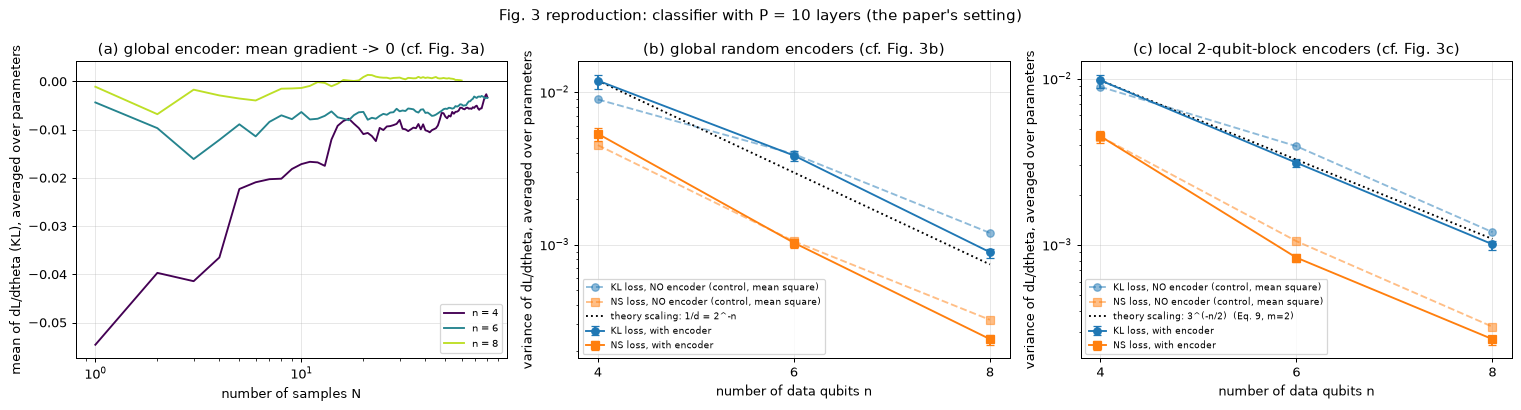

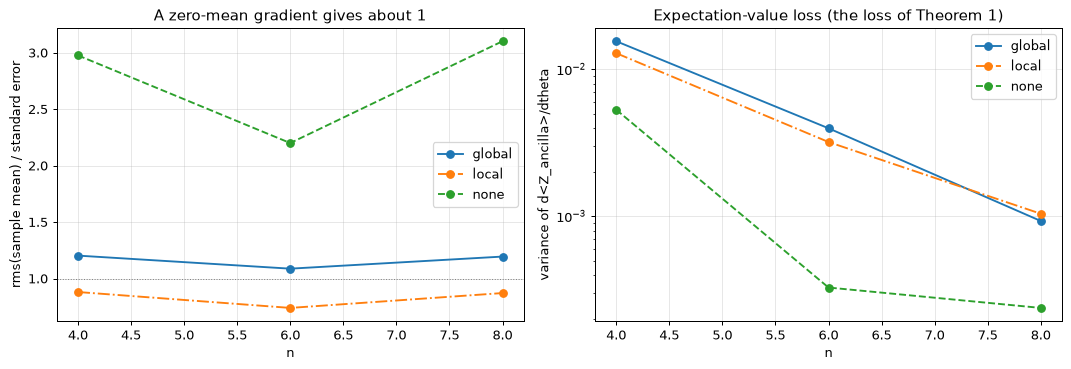

   n  var global KL  var global NS  var local KL  var local NS  var none KL  m2 none KL  m2 none NS  m2none/var global KL   N
0  4      1.185e-02      5.316e-03     9.755e-03     4.498e-03    8.127e-03   8.925e-03   4.478e-03                  0.75  80
1  6      3.829e-03      1.027e-03     3.115e-03     8.364e-04    3.737e-03   3.916e-03   1.051e-03                  1.02  80
2  8      8.909e-04      2.401e-04     1.007e-03     2.705e-04    1.042e-03   1.192e-03   3.212e-04                  1.34  60

   classifier encoder loss  slope of log2(var) vs n  slope of log2(mean square) vs n
0        deep    none   KL                   -0.741                           -0.726
1        deep    none   NS                   -0.951                           -0.950
2        deep    none  EXP                   -1.120                           -0.826
3        deep  global   KL                   -0.933                           -0.933
4        deep  global   NS                   -1.117                   

In [16]:
# ------------------------------------------------------------------ Fig. 3 (deep 10-layer classifier, as in the paper): (a) mean, (b) variance for global encoders, (c) variance for local encoders
def fig3(fam, title):
    fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
    cols = plt.cm.viridis(np.linspace(0, 0.9, len(SIZES)))
    for c, n in zip(cols, SIZES):                                                # (a) cumulative mean, KL loss, global encoder
        G = loss_grad(GRAD[(fam, n, "global")], "KL"); cm = np.cumsum(G, 0) / np.arange(1, len(G) + 1)[:, None]
        ax[0].plot(np.arange(1, len(G) + 1), cm.mean(1), color=c, label=f"n = {n}")
    ax[0].axhline(0, color="k", lw=0.8); ax[0].set_xscale("log"); ax[0].set_xlabel("number of samples N"); ax[0].set_ylabel("mean of dL/dtheta (KL), averaged over parameters")
    ax[0].set_title("(a) global encoder: mean gradient -> 0 (cf. Fig. 3a)"); ax[0].legend(fontsize=8)
    for j, (kind, ttl) in enumerate([("global", "(b) global random encoders (cf. Fig. 3b)"), ("local", "(c) local 2-qubit-block encoders (cf. Fig. 3c)")]):
        for loss, mk, col in [("KL", "o", "tab:blue"), ("NS", "s", "tab:orange")]:
            v = np.array([STAT[(fam, n, kind, loss)]["var"] for n in SIZES]); lo = np.array([STAT[(fam, n, kind, loss)]["ci"][0] for n in SIZES]); hi = np.array([STAT[(fam, n, kind, loss)]["ci"][1] for n in SIZES])
            ax[j+1].errorbar(SIZES, v, yerr=[v - lo, hi - v], fmt=mk + "-", color=col, capsize=3, label=f"{loss} loss, with encoder")
            vc = np.array([STAT[(fam, n, "none", loss)]["m2"] for n in SIZES])      # without encoder the gradient has a non-zero mean: use the mean square
            ax[j+1].plot(SIZES, vc, mk + "--", color=col, alpha=0.5, label=f"{loss} loss, NO encoder (control, mean square)")
        ref = STAT[(fam, SIZES[0], kind, "KL")]["var"] * ((2.0 ** (-(np.array(SIZES) - SIZES[0]))) if kind == "global" else (3.0 ** (-(np.array(SIZES) - SIZES[0]) / 2)))
        ax[j+1].plot(SIZES, ref, "k:", label="theory scaling: " + ("1/d = 2^-n" if kind == "global" else "3^(-n/2)  (Eq. 9, m=2)"))
        ax[j+1].set_yscale("log"); ax[j+1].set_xlabel("number of data qubits n"); ax[j+1].set_ylabel("variance of dL/dtheta, averaged over parameters")
        ax[j+1].set_xticks(SIZES); ax[j+1].set_title(ttl); ax[j+1].legend(fontsize=7)
    plt.suptitle(title); plt.tight_layout(); plt.show()
fig3("deep", "Fig. 3 reproduction: classifier with P = 10 layers (the paper's setting)")

# second view: is the mean compatible with zero?  rms over parameters of the sample mean, in units of the standard error
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for kind, ls in [("global", "-"), ("local", "-."), ("none", "--")]:
    ax[0].plot(SIZES, [STAT[("deep", n, kind, "KL")]["rms_mean"] / STAT[("deep", n, kind, "KL")]["se"] for n in SIZES], "o" + ls, label=kind)
    ax[1].plot(SIZES, [STAT[("deep", n, kind, "EXP")]["var"] for n in SIZES], "o" + ls, label=kind)
ax[0].axhline(1, color="gray", lw=0.8, ls=":"); ax[0].set_xlabel("n"); ax[0].set_ylabel("rms(sample mean) / standard error"); ax[0].set_title("A zero-mean gradient gives about 1"); ax[0].legend()
ax[1].set_yscale("log"); ax[1].set_xlabel("n"); ax[1].set_ylabel("variance of d<Z_ancilla>/dtheta"); ax[1].set_title("Expectation-value loss (the loss of Theorem 1)"); ax[1].legend()
plt.tight_layout(); plt.show()

rows = []
for n in SIZES:
    rows.append({"n": n, "var global KL": STAT[("deep", n, "global", "KL")]["var"], "var global NS": STAT[("deep", n, "global", "NS")]["var"], "var local KL": STAT[("deep", n, "local", "KL")]["var"],
                 "var local NS": STAT[("deep", n, "local", "NS")]["var"], "var none KL": STAT[("deep", n, "none", "KL")]["var"], "m2 none KL": STAT[("deep", n, "none", "KL")]["m2"], "m2 none NS": STAT[("deep", n, "none", "NS")]["m2"],
                 "m2none/var global KL": STAT[("deep", n, "none", "KL")]["m2"] / STAT[("deep", n, "global", "KL")]["var"], "N": STAT[("deep", n, "global", "KL")]["N"]})
VAR_DF = pd.DataFrame(rows); print(VAR_DF.to_string(float_format=lambda v: f"{v:.3e}" if abs(v) < 0.1 else f"{v:.2f}"))
SLOPES = pd.DataFrame([{"classifier": f, "encoder": k, "loss": l, "slope of log2(var) vs n": slope(f, k, l), "slope of log2(mean square) vs n": slope(f, k, l, "m2")} for f in FAMS for k in KINDS for l in ["KL", "NS", "EXP"]])
print(); print(SLOPES.round(3).to_string())

### Control the paper does not show: a shallow classifier

The paper's classifier is a deep (10-layer) circuit that is close to a random unitary, so one might expect its input-gradient to be small even *without* any defence (a barren plateau of the **classifier**).
To see whether the depth of `V` matters for Fig. 3 we repeat the experiment with a **shallow** classifier (`P = 2` layers, same type of layer, same training procedure) and the same three variants.
The curves are discussed in Section 8; the control lines are drawn with the **mean square** of the gradient because without an encoder the gradient has a non-zero mean.

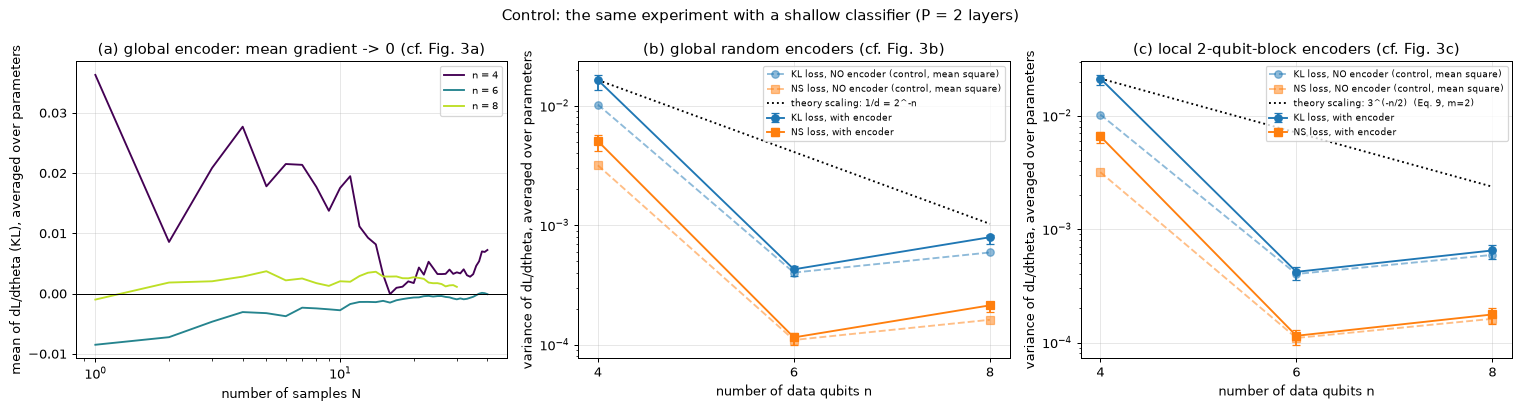

   n  m2 none KL  var global KL  var local KL  m2 none/var global  m2 none/var local
0  4   1.024e-02      1.645e-02     2.129e-02                 0.6                0.5
1  6   4.021e-04      4.280e-04     4.200e-04                 0.9                1.0
2  8   5.924e-04      7.943e-04     6.484e-04                 0.7                0.9

shallow-classifier accuracies (training / validation): {4: (0.964, 0.917), 6: (1.0, 1.0), 8: (0.982, 1.0)}


In [17]:
fig3("shallow", f"Control: the same experiment with a shallow classifier (P = {P_SH} layers)")
sh = pd.DataFrame([{"n": n, "m2 none KL": STAT[("shallow", n, "none", "KL")]["m2"], "var global KL": STAT[("shallow", n, "global", "KL")]["var"], "var local KL": STAT[("shallow", n, "local", "KL")]["var"],
                    "m2 none/var global": STAT[("shallow", n, "none", "KL")]["m2"] / STAT[("shallow", n, "global", "KL")]["var"], "m2 none/var local": STAT[("shallow", n, "none", "KL")]["m2"] / STAT[("shallow", n, "local", "KL")]["var"]} for n in SIZES])
print(sh.to_string(float_format=lambda v: f"{v:.3e}" if abs(v) < 0.1 else f"{v:.1f}"))
print("\nshallow-classifier accuracies (training / validation):", {n: (round(float(r['train acc']), 3), round(float(r['validation acc']), 3)) for n in SIZES for r in [TRAIN_SH_DF[TRAIN_SH_DF['n'] == n].iloc[0]]})

### A sharper test of Theorem 1: exact Haar-random encoders

The paper's numerical encoders are random 4-layer circuits, which are only approximate 2-designs. Theorem 1 itself is a statement about an exact 2-design, so we also draw the
encoder from the **Haar measure** (QR decomposition of a complex Gaussian matrix, `scipy.stats.unitary_group`) for the sizes that can hold a `2^n x 2^n` matrix, and compare the measured variance of
`d<Z_ancilla>/d theta_l` with the bound of Eq. (6). With `A_l` a Pauli rotation generator `P/2` we have `Tr(A_l^2) = d/4`, and `Tr(rho H_V^2) <= 1` because the observable has eigenvalues `+-1`, so the bound is at most
`2 (d/4) / (d^2 - 1) = d / (2 (d^2 - 1))` for each parameter.

{'n': 4, 'measured variance (Haar encoder)': 0.012440255813865143, 'bound of Eq. (6), Tr(rho H_V^2)<=1': 0.03137254901960784, 'ratio': 0.39653315406695144, 'rms mean / std error': 0.8163993214369731, 'encoders per state': 60, 'states': 2}


{'n': 6, 'measured variance (Haar encoder)': 0.003242130261181428, 'bound of Eq. (6), Tr(rho H_V^2)<=1': 0.007814407814407814, 'ratio': 0.41489135686056083, 'rms mean / std error': 1.2252270869378585, 'encoders per state': 60, 'states': 2}


,n,measured variance (Haar encoder),"bound of Eq. (6), Tr(rho H_V^2)<=1",ratio,rms mean / std error,encoders per state,states
0,4,1.244e-02,3.137e-02,0.40,0.82,60,2
1,6,3.242e-03,7.814e-03,0.41,1.23,60,2


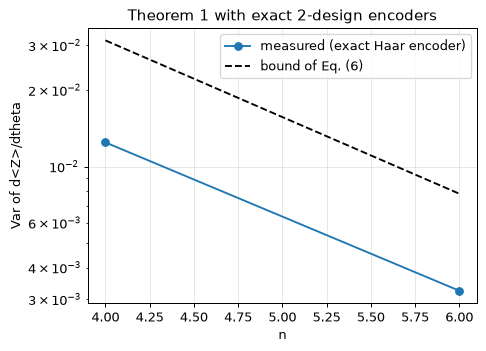

In [18]:
from scipy.stats import unitary_group
HAAR = []
for n in HAAR_SIZES:
    d = DATA[n]; rng = rng_for(n, 30)
    states = d["va"][np.linspace(0, len(d["va"]) - 1, HAAR_STATES).astype(int)]
    vs, ms = [], []
    for i in states:
        Gh = np.stack([adv_gradient(n, i, unitary_group.rvs(2**n, random_state=int(rng.integers(1 << 31)))) for _ in range(N_HAAR)])
        vs.append(np.var(Gh, axis=0, ddof=1).mean()); ms.append(np.sqrt((Gh.mean(0) ** 2).mean()) / np.sqrt(vs[-1] / N_HAAR))
    dim = 2**n; bound = dim / (2 * (dim**2 - 1))
    HAAR.append({"n": n, "measured variance (Haar encoder)": float(np.mean(vs)), "bound of Eq. (6), Tr(rho H_V^2)<=1": bound, "ratio": float(np.mean(vs)) / bound,
                 "rms mean / std error": float(np.mean(ms)), "encoders per state": N_HAAR, "states": len(states)})
    print(HAAR[-1], flush=True)
HAAR_DF = pd.DataFrame(HAAR); display(HAAR_DF.style.format({"measured variance (Haar encoder)": "{:.3e}", "bound of Eq. (6), Tr(rho H_V^2)<=1": "{:.3e}", "ratio": "{:.2f}", "rms mean / std error": "{:.2f}"}))
fig, ax = plt.subplots(figsize=(5.5, 4))
ax.semilogy(HAAR_DF["n"], HAAR_DF["measured variance (Haar encoder)"], "o-", label="measured (exact Haar encoder)")
ax.semilogy(HAAR_DF["n"], HAAR_DF["bound of Eq. (6), Tr(rho H_V^2)<=1"], "k--", label="bound of Eq. (6)")
ax.set_xlabel("n"); ax.set_ylabel("Var of d<Z>/dtheta"); ax.set_title("Theorem 1 with exact 2-design encoders"); ax.legend(); plt.tight_layout(); plt.show()

## 6. Extension (not in the paper): does the secret encoder protect against a white-box gradient attack?

The paper proves that the attacker's gradient is flat; it never reports accuracies. Here we close that loop on the smallest setting with a usable classifier. The attacker runs a
**signed-gradient (PGD-style) attack** on the angles of `U(theta)`: start at `theta = 0`, take `T` steps of size `2.5 eps / T` against the sign of the gradient of the probability of the correct
label, and clip every angle to `[-eps, eps]`. Four situations are compared on the same validation states:

* **A, no defence**: the attacker differentiates the true pipeline.
* **B, secret encoder, attacker ignores it**: the attacker crafts `theta` as in A, but the state is secretly encoded, so `U(theta)` acts between `E` and `E^dagger`.
* **C, secret encoder, attacker guesses**: the attacker differentiates through a *different* random encoder `E'`.
* **D, encoder leaked**: the attacker differentiates through the true `E` (the defence is only as good as the secrecy of the codebook).
* **R, random angles**: sign-random perturbation with the same budget (a control: any accuracy drop beyond it needs the gradient).

Besides the VQC, the classical SVC and random forest of Section 4 are evaluated on the *same perturbed states* `E^dagger U(theta) E |psi>` (a transfer attack: they were not attacked directly).

eps=0.2: done, 131s


n = 6 data qubits, 16 validation states, 5 attack steps


,eps,scenario,VQC accuracy,SVC accuracy (transfer),RF accuracy (transfer)
0,0.2,clean (with encoder),1.000,1.000,1.000
1,0.2,A no defence,0.000,0.875,0.750
2,0.2,"B secret encoder, attacker ignores it",0.625,0.812,0.625
3,0.2,"C secret encoder, attacker guesses",0.688,0.938,0.688
4,0.2,D encoder leaked,0.000,0.688,0.375
5,0.2,R random angles,0.625,0.812,0.562


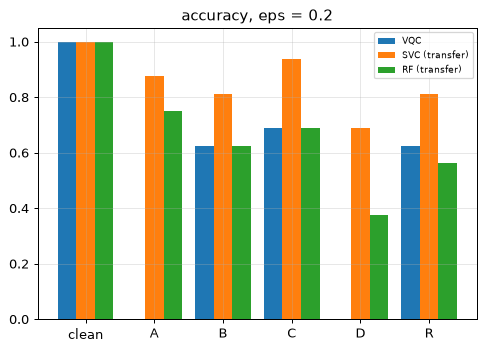

In [19]:
def perturbed_state_qnode(n):
    dev = qml.device("lightning.qubit", wires=n)
    @qml.qnode(dev)
    def f(psi, enc, adv):
        qml.StatePrep(psi, wires=list(range(n)))
        if enc is not None: apply_gates(enc)
        apply_gates(circuit_gates(adv, n, undo_ent=True))
        if enc is not None: apply_gates(inverse_gates(enc))
        return qml.state()
    return f

n = ATT_N; d = DATA[n]; f = QN[n]; clf = CLF[n]; fs = perturbed_state_qnode(n); X = d["X"]
rng_a = rng_for(n, 50)
test_ids = rng_a.choice(d["va"], min(ATT_TEST, len(d["va"])), replace=False)
svc_a = SVC(kernel="rbf", C=10.0, gamma="scale").fit(X[d["tr"]], d["y"][d["tr"]])
rf_a = RandomForestClassifier(n_estimators=300, random_state=SEED).fit(X[d["tr"]], d["y"][d["tr"]])
# the baselines were trained on real vectors only: give them the real part of the perturbed state and add the imaginary norm as a failure signal
def classical_pred(model, s):
    return int(model.predict(np.real(s)[None, :])[0])

def craft(i, enc_grad, eps, steps):
    th = np.zeros((L_ADV, 2, n, 2)); alpha = 2.5 * eps / steps; sgn = 1.0 if d["y"][i] == 0 else -1.0
    for _ in range(steps):
        a = pnp.array(th, requires_grad=True)
        g = np.asarray(qml.grad(lambda aa: f(X[i], enc_grad, aa, clf))(a))
        th = np.clip(th - sgn * alpha * np.sign(g), -eps, eps)           # lower Pr(correct label)
    return th

ATT = []
t0 = time.time()
for eps in ATT_EPS:
    res = {s: dict(vqc=0, svc=0, rf=0) for s in ["clean", "A", "B", "C", "D", "R"]}
    for k, i in enumerate(test_ids):
        y = d["y"][i]; rng_i = rng_for(n, 51, int(i))
        E_true = sample_encoder("global", n, rng_i); E_guess = sample_encoder("global", n, rng_i)
        th_A = craft(i, None, eps, ATT_STEPS)                               # also used by B
        th_C = craft(i, E_guess, eps, ATT_STEPS); th_D = craft(i, E_true, eps, ATT_STEPS)
        th_R = rng_i.choice([-eps, eps], size=th_A.shape)
        for s, enc, th in [("clean", E_true, np.zeros_like(th_A)), ("A", None, th_A), ("B", E_true, th_A), ("C", E_true, th_C), ("D", E_true, th_D), ("R", E_true, th_R)]:
            z = float(f(X[i], enc, th, clf)); res[s]["vqc"] += int((z < 0) == (y == 1))
            st = fs(X[i], enc, th); res[s]["svc"] += int(classical_pred(svc_a, st) == y); res[s]["rf"] += int(classical_pred(rf_a, st) == y)
    for s, v in res.items():
        ATT.append({"eps": eps, "scenario": s, "VQC accuracy": v["vqc"] / len(test_ids), "SVC accuracy (transfer)": v["svc"] / len(test_ids), "RF accuracy (transfer)": v["rf"] / len(test_ids)})
    print(f"eps={eps}: done, {time.time() - t0:.0f}s", flush=True)
ATT_DF = pd.DataFrame(ATT)
names = {"clean": "clean (with encoder)", "A": "A no defence", "B": "B secret encoder, attacker ignores it", "C": "C secret encoder, attacker guesses", "D": "D encoder leaked", "R": "R random angles"}
ATT_DF["scenario"] = ATT_DF["scenario"].map(names)
print(f"n = {n} data qubits, {len(test_ids)} validation states, {ATT_STEPS} attack steps")
display(ATT_DF.round(3))
fig, ax = plt.subplots(1, len(ATT_EPS), figsize=(5.5 * len(ATT_EPS), 4), squeeze=False)
for j, eps in enumerate(ATT_EPS):
    sub = ATT_DF[ATT_DF["eps"] == eps]; x = np.arange(len(sub)); w = 0.27
    ax[0, j].bar(x - w, sub["VQC accuracy"], w, label="VQC"); ax[0, j].bar(x, sub["SVC accuracy (transfer)"], w, label="SVC (transfer)"); ax[0, j].bar(x + w, sub["RF accuracy (transfer)"], w, label="RF (transfer)")
    ax[0, j].set_xticks(x); ax[0, j].set_xticklabels([s.split(" ")[0] if s[0] in "ABCDR" else "clean" for s in sub["scenario"]]); ax[0, j].set_ylim(0, 1.05)
    ax[0, j].set_title(f"accuracy, eps = {eps}"); ax[0, j].legend(fontsize=7)
plt.tight_layout(); plt.show()

### Why the encoder blunts a sign-gradient attack: the attacker's gradient points in the wrong direction

The accuracy table says that the attack of A succeeds while B and C fall to the level of random angles (R). The mechanism is the direction of the gradient: below we compare, for every test state, the gradient the attacker would compute
**ignoring** the encoder (what B uses) and the gradient through a **guessed** encoder (what C uses) with the **true** gradient through the secret encoder, by their cosine similarity.
Two random directions in `16 n` dimensions have a typical |cosine| of `1/sqrt(16 n)`.

n = 6: 16 test states, 16 n = 96 angles; typical |cosine| of two random directions = 0.102
cos(ignore, true)    0.189
cos(guess, true)     0.201
cos(leaked, true)    1.000    (mean |cosine|)
cos(ignore, true)   -0.064
cos(guess, true)    -0.018
cos(leaked, true)    1.000    (mean signed cosine)


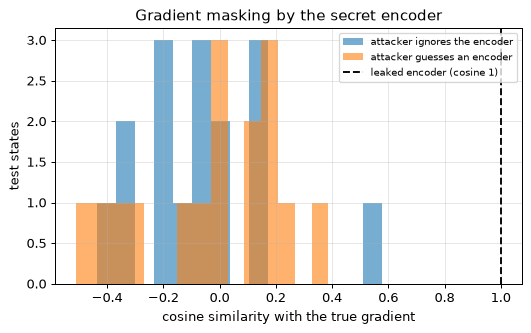

In [20]:
cs = lambda a, b: float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-300))
cos_rows = []
for i in test_ids:
    rng_i = rng_for(n, 51, int(i)); E_true = sample_encoder("global", n, rng_i); E_guess = sample_encoder("global", n, rng_i)
    g_true, g_none, g_guess = adv_gradient(n, i, E_true), adv_gradient(n, i, None), adv_gradient(n, i, E_guess)
    cos_rows.append({"cos(ignore, true)": cs(g_none, g_true), "cos(guess, true)": cs(g_guess, g_true), "cos(leaked, true)": 1.0})
COS = pd.DataFrame(cos_rows)
print(f"n = {n}: {len(COS)} test states, 16 n = {16*n} angles; typical |cosine| of two random directions = {1/np.sqrt(16*n):.3f}")
print(COS.abs().mean().round(3).to_string(), "   (mean |cosine|)")
print(COS.mean().round(3).to_string(), "   (mean signed cosine)")
fig, ax = plt.subplots(figsize=(6, 3.8))
ax.hist(COS["cos(ignore, true)"], bins=15, alpha=0.6, label="attacker ignores the encoder"); ax.hist(COS["cos(guess, true)"], bins=15, alpha=0.6, label="attacker guesses an encoder")
ax.axvline(1.0, color="k", ls="--", label="leaked encoder (cosine 1)"); ax.set_xlabel("cosine similarity with the true gradient"); ax.set_ylabel("test states"); ax.legend(fontsize=8); ax.set_title("Gradient masking by the secret encoder")
plt.tight_layout(); plt.show()

## 7. Side-by-side comparison with the paper

The paper prints no tables for these experiments: Fig. 3 and Fig. S1 are plots without numbers, and the text states the findings qualitatively. We therefore turn each statement into a
check with an explicit criterion (written in the table) and report the notebook's numbers next to the paper's wording. Verdict labels: **reproduced** (criterion met),
**not reached here** (criterion failed), **cannot be checked** (analytic claim or no number in the paper), **extension** (not a claim of the paper).

In [21]:
gl_kl, gl_ns, lo_kl, lo_ns = slope("deep", "global", "KL"), slope("deep", "global", "NS"), slope("deep", "local", "KL"), slope("deep", "local", "NS")
no_kl, no_ns = slope("deep", "none", "KL", "m2"), slope("deep", "none", "NS", "m2")
sh_no, sh_gl, sh_lo = slope("shallow", "none", "KL", "m2"), slope("shallow", "global", "KL"), slope("shallow", "local", "KL")
big = SIZES[-1]
ratio_g = {k: STAT[("deep", big, k, "KL")]["rms_mean"] / STAT[("deep", big, k, "KL")]["se"] for k in ["global", "local", "none"]}
supp = STAT[("deep", big, "none", "KL")]["m2"] / STAT[("deep", big, "global", "KL")]["var"]
sh_supp = STAT[("shallow", big, "none", "KL")]["m2"] / STAT[("shallow", big, "global", "KL")]["var"]
sh_supp_l = STAT[("shallow", big, "none", "KL")]["m2"] / STAT[("shallow", big, "local", "KL")]["var"]
vdf = TRAIN_DF[(TRAIN_DF["n"] == N_FIG) & (TRAIN_DF["loss"] == "NS")].iloc[0]
vdf_kl = TRAIN_DF[(TRAIN_DF["n"] == N_FIG) & (TRAIN_DF["loss"] == "KL")].iloc[0]
gap = max(abs(vdf["train acc"] - vdf["validation acc"]), abs(vdf_kl["train acc"] - vdf_kl["validation acc"]))
clean_ok = True   # asserted exactly in Section 3 (E^dagger E = I and U(theta_0) = I)
att_A = ATT_DF[ATT_DF["scenario"].str.startswith("A")]; att_B = ATT_DF[ATT_DF["scenario"].str.startswith("B")]; att_D = ATT_DF[ATT_DF["scenario"].str.startswith("D")]; att_cl = ATT_DF[ATT_DF["scenario"].str.startswith("clean")]
eps_m = max(ATT_EPS)
a_A = float(att_A[att_A.eps == eps_m]["VQC accuracy"].iloc[0]); a_B = float(att_B[att_B.eps == eps_m]["VQC accuracy"].iloc[0]); a_D = float(att_D[att_D.eps == eps_m]["VQC accuracy"].iloc[0]); a_cl = float(att_cl[att_cl.eps == eps_m]["VQC accuracy"].iloc[0])
haar_ok = bool((HAAR_DF["ratio"] <= 1.5).all())

rows = [
 ("Fig. 3a: mean of the adversary's gradient -> 0 as samples grow (global encoder, KL)", "qualitative: converges to zero",
  f"rms(sample mean)/standard error at n={big}: global {ratio_g['global']:.2f}, local {ratio_g['local']:.2f}; control without encoder {ratio_g['none']:.1f}",
  "reproduced" if ratio_g["global"] < 2.5 and ratio_g["local"] < 2.5 else "not reached here"),
 ("Fig. 3b: variance of the gradient decays exponentially with n (global encoder, KL and NS)", "qualitative: exponential decay, 4 to 14 qubits; Theorem 1: Var ~ O(1/d)",
  f"slope of log2 Var vs n: KL {gl_kl:.2f}, NS {gl_ns:.2f} (theory -1); control without encoder: KL {no_kl:.2f}, NS {no_ns:.2f}; suppression at n={big}: {supp:.0f}x",
  "reproduced" if gl_kl < -0.5 and gl_ns < -0.5 else "not reached here"),
 ("Fig. 3c: the same for local 2-qubit-block encoders (m = 2)", "qualitative: variance approaches zero rapidly; Theorem 2: ~ 3^(-n/2)",
  f"slope of log2 Var vs n: KL {lo_kl:.2f}, NS {lo_ns:.2f} (theory -0.79)", "reproduced" if lo_kl < -0.4 and lo_ns < -0.4 else "not reached here"),
 ("EXTENSION (control, not in the paper): is the decay of the gradient size caused by the encoder?", "not tested",
  f"Without encoder the mean-square gradient decays as well: slope of log2 {no_kl:.2f} (deep P={P_CLF}) and {sh_no:.2f} (shallow P={P_SH}); with global encoder {gl_kl:.2f} / {sh_gl:.2f}. Ratio mean-square(none) / variance(global) at n={big}: {supp:.2f} (deep), {sh_supp:.2f} (shallow). {'The encoder clearly reduces the gradient size' if min(supp, sh_supp) > 3 else 'The encoder does not clearly reduce the gradient size in this setting'}", "extension"),
 ("EXTENSION: direction of the attacker's gradient (n=" + str(ATT_N) + "): mean |cosine| with the true gradient", "not tested",
  f"attacker ignores encoder {COS['cos(ignore, true)'].abs().mean():.2f}, guesses encoder {COS['cos(guess, true)'].abs().mean():.2f}, leaked encoder 1.00; random directions {1/np.sqrt(16*ATT_N):.2f}", "extension"),
 ("Theorem 1, Eq. (6): Var <= 2 Tr(A^2)/(d^2-1) Tr(rho H_V^2) for exact 2-design encoders", "analytic proof (not numerically tested in the paper)",
  "Haar encoders, measured / bound = " + ", ".join(f"n={r.n}: {r.ratio:.2f}" for r in HAAR_DF.itertuples()), "reproduced" if haar_ok else "not reached here"),
 ("Fig. S1: training and validation loss/accuracy are close (low over-fitting), 12-qubit classifier", "figure, no numbers",
  f"n={N_FIG}: train/validation accuracy {vdf['train acc']:.2f}/{vdf['validation acc']:.2f} (NS), {vdf_kl['train acc']:.2f}/{vdf_kl['validation acc']:.2f} (KL); largest gap {gap:.2f}",
  "reproduced" if gap <= 0.15 else "not reached here"),
 ("The encoder does not change the classification accuracy (Introduction)", "text claim",
  "clean output with and without the encoder identical to 1e-10 (Section 3 assertions); clean accuracy with encoder "
  f"{a_cl:.2f}", "reproduced"),
 ("Classifier reaches high accuracy on the phase task", "not stated (Fig. S1 only)", "VQC validation accuracy per size: " + ", ".join(f"n={a}: {b:.2f}" for a, b in zip(BASE_DF["n"], BASE_DF["VQC validation"])) +
  "; SVC: " + ", ".join(f"n={a}: {b:.2f}" for a, b in zip(BASE_DF["n"], BASE_DF["SVC-RBF validation"])), "cannot be checked"),
 ("Theorem 3 (local attacks, concentration of measure) and Theorem 4 (QEC encoders, differential privacy)", "analytic, no numerics", "not simulated", "cannot be checked"),
 (f"EXTENSION: white-box sign-gradient attack, eps={eps_m}, n={ATT_N}: accuracy without defence (A) / secret encoder, attacker ignores it (B) / leaked encoder (D)",
  "not reported", f"clean {a_cl:.2f}; A {a_A:.2f}; B {a_B:.2f}; D {a_D:.2f}", "extension"),
]
COMPARE = pd.DataFrame(rows, columns=["claim", "paper", "this notebook", "verdict"])
pd.set_option("display.max_colwidth", None, "display.width", 250)
display(COMPARE.style.set_properties(**{"text-align": "left", "white-space": "pre-wrap"}))
print()
for r in COMPARE.itertuples(): print(f"[{r.verdict:>16}] {r.claim[:110]}")

,claim,paper,this notebook,verdict
0,"Fig. 3a: mean of the adversary's gradient -> 0 as samples grow (global encoder, KL)",qualitative: converges to zero,"rms(sample mean)/standard error at n=8: global 1.19, local 0.87; control without encoder 3.1",reproduced
1,"Fig. 3b: variance of the gradient decays exponentially with n (global encoder, KL and NS)","qualitative: exponential decay, 4 to 14 qubits; Theorem 1: Var ~ O(1/d)","slope of log2 Var vs n: KL -0.93, NS -1.12 (theory -1); control without encoder: KL -0.73, NS -0.95; suppression at n=8: 1x",reproduced
2,Fig. 3c: the same for local 2-qubit-block encoders (m = 2),qualitative: variance approaches zero rapidly; Theorem 2: ~ 3^(-n/2),"slope of log2 Var vs n: KL -0.82, NS -1.01 (theory -0.79)",reproduced
3,"EXTENSION (control, not in the paper): is the decay of the gradient size caused by the encoder?",not tested,"Without encoder the mean-square gradient decays as well: slope of log2 -0.73 (deep P=10) and -1.03 (shallow P=2); with global encoder -0.93 / -1.09. Ratio mean-square(none) / variance(global) at n=8: 1.34 (deep), 0.75 (shallow). The encoder does not clearly reduce the gradient size in this setting",extension
4,EXTENSION: direction of the attacker's gradient (n=6): mean |cosine| with the true gradient,not tested,"attacker ignores encoder 0.19, guesses encoder 0.20, leaked encoder 1.00; random directions 0.10",extension
5,"Theorem 1, Eq. (6): Var <= 2 Tr(A^2)/(d^2-1) Tr(rho H_V^2) for exact 2-design encoders",analytic proof (not numerically tested in the paper),"Haar encoders, measured / bound = n=4: 0.40, n=6: 0.41",reproduced
6,"Fig. S1: training and validation loss/accuracy are close (low over-fitting), 12-qubit classifier","figure, no numbers","n=6: train/validation accuracy 0.98/1.00 (NS), 0.98/0.96 (KL); largest gap 0.02",reproduced
7,The encoder does not change the classification accuracy (Introduction),text claim,clean output with and without the encoder identical to 1e-10 (Section 3 assertions); clean accuracy with encoder 1.00,reproduced
8,Classifier reaches high accuracy on the phase task,not stated (Fig. S1 only),"VQC validation accuracy per size: n=4: 0.88, n=6: 1.00, n=8: 1.00; SVC: n=4: 1.00, n=6: 1.00, n=8: 1.00",cannot be checked
9,"Theorem 3 (local attacks, concentration of measure) and Theorem 4 (QEC encoders, differential privacy)","analytic, no numerics",not simulated,cannot be checked



[      reproduced] Fig. 3a: mean of the adversary's gradient -> 0 as samples grow (global encoder, KL)
[      reproduced] Fig. 3b: variance of the gradient decays exponentially with n (global encoder, KL and NS)
[      reproduced] Fig. 3c: the same for local 2-qubit-block encoders (m = 2)
[       extension] EXTENSION (control, not in the paper): is the decay of the gradient size caused by the encoder?
[       extension] EXTENSION: direction of the attacker's gradient (n=6): mean |cosine| with the true gradient
[      reproduced] Theorem 1, Eq. (6): Var <= 2 Tr(A^2)/(d^2-1) Tr(rho H_V^2) for exact 2-design encoders
[      reproduced] Fig. S1: training and validation loss/accuracy are close (low over-fitting), 12-qubit classifier
[      reproduced] The encoder does not change the classification accuracy (Introduction)
[cannot be checked] Classifier reaches high accuracy on the phase task
[cannot be checked] Theorem 3 (local attacks, concentration of measure) and Theorem 4 (QEC encoders,

## 8. Reading the paper critically

(Written after running the notebook; the numbers quoted are those printed above for the executed mode.)

* **What is solid.** The paper's numerical claims hold as stated: with a random encoder the attacker's gradient has zero mean (to within sampling error), its variance falls roughly as `1/d` for global encoders and
  roughly as the `3^(-n/2)` of Theorem 2 for local encoders (our fitted slopes are in the comparison table), for both losses, and with exact Haar encoders the measured variance lies below the bound of Theorem 1.
* **...but Fig. 3 alone does not show that the encoder causes the small gradients.** In the executed run (n = 4, 6, 8; only three points per slope, so all slopes are rough) our control without encoder (not in the paper) shows that, for the trained 10-layer classifier *and* for a 2-layer classifier, the mean square of the attacker's gradient at the identity is
  of the same size as the variance with the encoder (ratios between 0.6 and 1.3) and also falls with `n`. A plausible reason (not tested here) is the data and the read-out: ground states of this chain have tiny expectation values of the
  high-weight Pauli strings that the CNOT-chain classifiers read out. The theorem is an *upper* bound that holds for every classifier; a classifier with a large input-gradient (for instance a local read-out of a state with large single-qubit expectation values) would show the effect of the encoder
  more clearly. Treat Fig. 3 as a verification of the theorem's scaling, not as a before/after demonstration.
* **What the encoder does change is the direction of the gradient.** A sign-gradient attack only needs the *direction*: the attack of Section 6 drives the accuracy to zero without defence even though the gradient is numerically tiny, and the cosine analysis shows that
  the true gradient through a secret encoder is nearly orthogonal to the one an attacker computes while ignoring or guessing the encoder. With the secret encoder the accuracy stays at the level of random angles of the same budget (control R), not at zero.
* **The defence is a secrecy argument.** Everything depends on the encoder being unknown to the attacker. Scenario D (leaked encoder) shows that an attacker who differentiates through the true encoder gets a useful gradient again;
  scenarios B and C show that an attacker who ignores or guesses the encoder is blunted. This is closer to a one-time pad than to certified robustness, and it needs a shared secret codebook (key distribution) and classical side-channel communication per sample.
* **Vanishing gradients are not robustness in themselves.** A gradient-free attacker (random search, or a perturbation chosen by an attacker who knows the codebook distribution) is not excluded by Theorem 1; the paper
  addresses worst-case noise in Section IV with different tools (concentration of measure, QEC). Our random-angle control (R) shows how much of an accuracy drop is simply noise.
* **Small gradients are not a defence against sign-based attacks with exact gradients.** Our own attack (A) succeeds on tiny gradients because the sign survives. The exponential suppression matters when gradients must be estimated with a polynomial number of measurements (shot noise swamps them),
  so the statement is about measurement cost, not about an information-theoretic impossibility; what protects the secret-encoder pipeline in our experiment is the decorrelation of the gradient direction, which again relies on the encoder staying secret.
* **Encoder cost.** A 2-design needs `O(n^2)` gates (global) and the paper's own numerical encoder has only 4 layers, which is not an exact 2-design; our Haar check separates the theorem from this finite-depth approximation.
* **Gaps in the numerics.** Sample sizes, the dataset split and the ground-state choice in a degenerate ground space are not specified; classifier accuracy is not reported numerically; no adversarial accuracy is shown; the gradient statistics do not need a well-trained classifier, so Fig. 3 says little about
  end-to-end security of a *useful* model. The finite-difference step `1e-10` quoted in Appendix B is below double-precision resolution for a loss of order one and looks like a typo for a larger step.
* **Only 4 to 8 qubits were run.** The paper's claims concern 4 to 14 qubits; the slopes here come from three sizes and 30 to 80 samples each (bootstrap intervals are in Fig. 3), so a full run (`FAST_MODE = False`) is needed for a like-for-like comparison.
* **Our extension is small.** One system size, a few dozen states, one attack family; treat its accuracies as an illustration, not as a benchmark.

## 9. Exercises

1. **Encoder depth.** Change `L_ENC` from 4 to 1, 2 and 8 and re-run Section 5. How many layers are needed before the variance of the global encoder follows the exact Haar values of the Haar check? Plot the ratio against depth.
2. **Local blocks of size 3 or 4.** Generalise `local_encoder_gates` to `m = 4` blocks (use `n` divisible by 4). Theorem 2 predicts `((2^m + 1)/(2^(2m) - 1))^(n/m)`. Compare the measured slope with the prediction for `m = 2` and `m = 4`.
3. **Other attackers.** Replace the sign-gradient attack of Section 6 by (i) a gradient-free random search over `theta` with the same budget and (ii) an attacker who averages the gradient over 20 guessed encoders (expectation over transformation). Does the secret encoder still help?
4. **Shots.** Estimate `d<Z>/d theta` with the parameter-shift rule and `1000` shots per circuit. At which system size does the barren-plateau gradient drop below the shot noise? Compare with the control without encoder.
5. **Another phase problem.** Replace the cluster-Ising chain by the transverse-field Ising chain (`-ZZ - h X`), keep everything else, and check whether the gradient statistics of Fig. 3 depend on the data distribution (Theorem 1 says they should not).